# Smart Logistics Delay Prediction

## Project Overview
This project focuses on analyzing e-commerce delivery data and building a machine learning model to predict whether an order will be delivered late.

The objective is to identify potential delivery delays in advance so that logistics teams can take proactive actions and improve customer satisfaction.

## Business Problem
Late deliveries negatively impact customer satisfaction, trust, and the overall e-commerce experience. Identifying potentially delayed orders in advance can help businesses prioritize shipments, manage logistics operations, and reduce delivery-related issues.

## Project Objectives
- Analyze historical e-commerce delivery data.
- Identify patterns associated with delivery delays.
- Perform data cleaning and feature engineering.
- Build classification models to predict late deliveries.
- Evaluate models using Precision, Recall, and F1-score, considering class imbalance.
- Explore threshold tuning to improve late-delivery detection.

## Dataset
The project uses the Olist Brazilian E-Commerce dataset.

## Target Variable
- `is_late = 0` — On-time delivery
- `is_late = 1` — Late delivery

## Evaluation Focus
Since late deliveries represent a minority of observations, accuracy alone is not sufficient. The primary focus is on **Precision, Recall, and F1-score** for the late-delivery class.

In [13]:
print('hello 1')
print('hello 2')
print('Welcome to Smart Logistics Data Science Project!')

hello 1
hello 2
Welcome to Smart Logistics Data Science Project!


# Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand delivery patterns, identify data quality issues, explore feature distributions, and investigate factors associated with late deliveries.

The analysis focused on:
- Distribution of on-time and late deliveries
- Actual vs. estimated delivery time
- Delivery delay distribution and outliers
- Geographical delivery patterns across customer and seller states
- Order value, freight charges, and number of items
- Relationships between numerical features and late-delivery outcomes
- Correlation between selected features

In [14]:
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn

print('Pandas version:', pd.__version__)
print('Numpy version:', np.__version__)
print('Matplotlib version:', matplotlib.__version__)
print('Seaborn version:', sns.__version__)
print('Scikit-learn version:', sklearn.__version__)
print("\nAll libraries are imported successfully and their versions are printed.")

Pandas version: 3.1.1
Numpy version: 2.5.5
Matplotlib version: 3.11.2
Seaborn version: 0.13.2
Scikit-learn version: 1.9.1

All libraries are imported successfully and their versions are printed.


In [ ]:
import os
print("Current working directory:", os.getcwd())

Current working directory: c:\Users\saksh\datascince\Smart-Logistics-Delay-Prediction\notebooks


In [ ]:
import os
data_path = "../data/raw"
print(os.path.abspath(data_path))
print(os.path.exists(data_path))

c:\Users\saksh\datascince\Smart-Logistics-Delay-Prediction\data\raw
True


In [ ]:
import os
data_path = "../data/raw"
files = os.listdir(data_path)
print("Total files", len(files))
print("\nDataset files:")
for file in files:
    print(file)

Total files 9

Dataset files:
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_orders_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [ ]:
import pandas as pd
#load orders dataset
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
#Dataset  shape checking
print("Rows and Columns in the dataset:", orders.shape)

#COlumn names 
print("\nColumn Names:")
print(orders.columns.tolist())

#Dataset information check 
print("\nDataset Information:")
orders.info()


Rows and Columns in the dataset: (99441, 8)

Column Names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [ ]:
#check dublicate rows
print("\nDuplicate Rows in the dataset:", orders.duplicated().sum())

#check total records
print("\nTotal records in the dataset:", len(orders))


Duplicate Rows in the dataset: 0

Total records in the dataset: 99441


In [ ]:
missing_values = orders.isnull().sum()
missing_percentage = (missing_values / len(orders)) * 100
missing_report = pd.DataFrame({'Missing Values': missing_values, 'Percentage': missing_percentage.round(2)})

missing_report

,Missing Values,Percentage
order_id,0,0.00
customer_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98
order_estimated_delivery_date,0,0.00


In [ ]:
# check order status for missing delivery dates
print("order status with customer delivery date:")
print(orders[orders['order_delivered_customer_date'].isnull()]['order_status'].value_counts())
print("\norder status with seller delivery date:")
print(orders[orders['order_delivered_carrier_date'].isnull()]['order_status'].value_counts())

order status with customer delivery date:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

order status with seller delivery date:
order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64


In [ ]:
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")

In [ ]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [ ]:
orders[['order_status',
         'order_purchase_timestamp',
         'order_approved_at',
         'order_delivered_carrier_date',
         'order_delivered_customer_date',
         'order_estimated_delivery_date']].head(10)

,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
5,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00
6,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00
7,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00
8,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00
9,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00


In [ ]:
orders.head(10)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00


In [ ]:
orders[['order_status',
         'order_purchase_timestamp',
         'order_approved_at',
         'order_delivered_carrier_date',
         'order_delivered_customer_date',
         'order_estimated_delivery_date']].head(10)

,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
5,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00
6,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00
7,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00
8,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00
9,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00


In [ ]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [ ]:
missing_summary = pd.DataFrame({
    'missing_count': orders.isnull().sum(),
    'missing_percentage': (orders.isnull().sum() / len(orders)) * 100
})

missing_summary.sort_values('missing_percentage', ascending=False)

,missing_count,missing_percentage
order_delivered_customer_date,2965,2.981668
order_delivered_carrier_date,1783,1.793023
order_approved_at,160,0.160899
order_id,0,0.000000
order_purchase_timestamp,0,0.000000
order_status,0,0.000000
customer_id,0,0.000000
order_estimated_delivery_date,0,0.000000


In [ ]:
orders.groupby('order_status')[
    [
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date'
    ]
].apply(lambda x: x.isnull().sum())

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


In [ ]:
orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [ ]:
orders['order_status'].value_counts(normalize=True) * 100

order_status
delivered      97.020344
shipped         1.113223
canceled        0.628513
unavailable     0.612423
invoiced        0.315765
processing      0.302692
created         0.005028
approved        0.002011
Name: proportion, dtype: float64

In [ ]:
orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [ ]:
orders['order_status'].value_counts(normalize=True) * 100

order_status
delivered      97.020344
shipped         1.113223
canceled        0.628513
unavailable     0.612423
invoiced        0.315765
processing      0.302692
created         0.005028
approved        0.002011
Name: proportion, dtype: float64

In [ ]:
status_summary = pd.DataFrame({
    'count': orders['order_status'].value_counts(),
    'percentage': orders['order_status'].value_counts(normalize=True) * 100
})

status_summary

,count,percentage
order_status,,
delivered,96478,97.020344
shipped,1107,1.113223
canceled,625,0.628513
unavailable,609,0.612423
invoiced,314,0.315765
processing,301,0.302692
created,5,0.005028
approved,2,0.002011


In [ ]:
status_summary = pd.DataFrame({
    'count': orders['order_status'].value_counts(),
    'percentage': orders['order_status'].value_counts(normalize=True) * 100
})

status_summary

,count,percentage
order_status,,
delivered,96478,97.020344
shipped,1107,1.113223
canceled,625,0.628513
unavailable,609,0.612423
invoiced,314,0.315765
processing,301,0.302692
created,5,0.005028
approved,2,0.002011


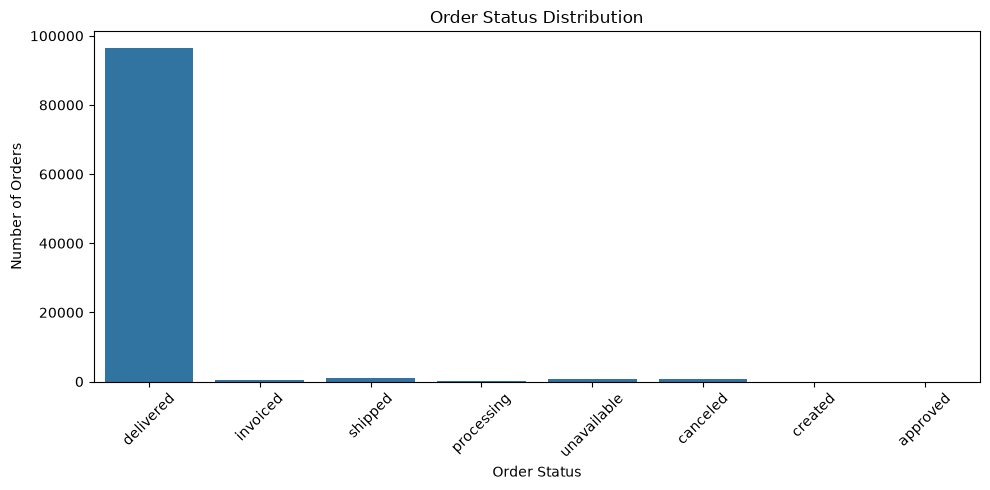

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(data=orders, x='order_status')

plt.title('Order Status Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

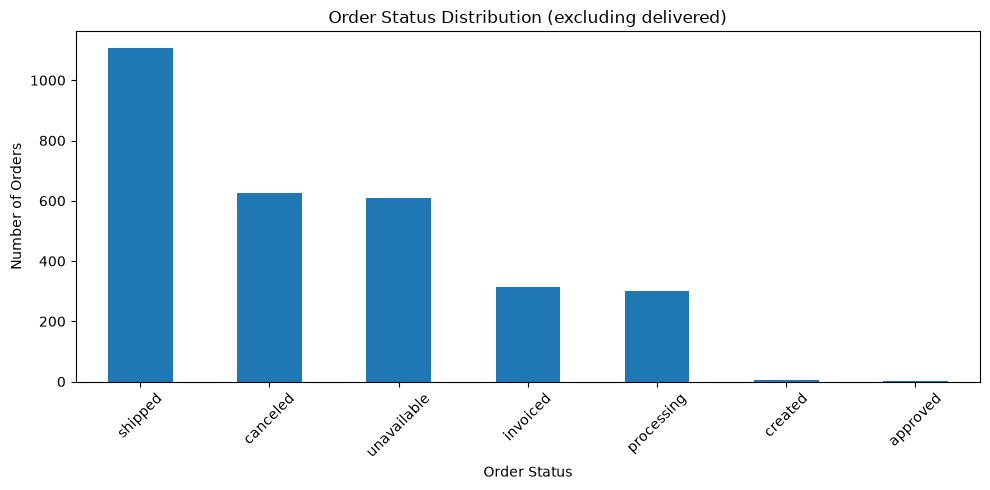

In [ ]:
status_counts = orders['order_status'].value_counts()

status_counts.drop('delivered').plot(
    kind='bar',
    figsize=(10, 5),
    title='Order Status Distribution (excluding delivered)'
)

plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

In [ ]:
orders[date_columns].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

\[
\text{Delay Days} = \text{Actual Delivery Date} - \text{Estimated Delivery Date}
\]

- Positive value → Late delivery
- Negative value → Early delivery
- Zero → Delivered on estimated date
Step 1 — Valid delivered orders select karo
Hum sirf delivered orders lenge jinke actual aur estimated delivery dates available hain.

In [ ]:
delivered_orders = orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_customer_date'].notnull()) &
    (orders['order_estimated_delivery_date'].notnull())
].copy()

.copy() kyun? Filtered DataFrame ki independent copy banane ke liye, taaki hum usme naye columns safely add kar sakein.

In [ ]:
delivered_orders['delivery_delay_days'] = (
    delivered_orders['order_delivered_customer_date'].dt.normalize() -
    delivered_orders['order_estimated_delivery_date'].dt.normalize()
).dt.days

In [ ]:
delivered_orders[
    ['order_delivered_customer_date',
     'order_estimated_delivery_date',
     'delivery_delay_days']
].head(10)

,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days
0,2017-10-10 21:25:13,2017-10-18,-8
1,2018-08-07 15:27:45,2018-08-13,-6
2,2018-08-17 18:06:29,2018-09-04,-18
3,2017-12-02 00:28:42,2017-12-15,-13
4,2018-02-16 18:17:02,2018-02-26,-10
5,2017-07-26 10:57:55,2017-08-01,-6
7,2017-05-26 12:55:51,2017-06-07,-12
8,2017-02-02 14:08:10,2017-03-06,-32
9,2017-08-16 17:14:30,2017-08-23,-7
10,2017-05-29 11:18:31,2017-06-07,-9


In [ ]:
delivered_orders['delivery_delay_days'].describe()

count    96470.000000
mean       -11.875889
std         10.182105
min       -147.000000
25%        -17.000000
50%        -12.000000
75%         -7.000000
max        188.000000
Name: delivery_delay_days, dtype: float64

3. Ab next step — Late vs On-time orders
Ab hum delay days ko business-friendly categories mein convert karenge.
- delivery_delay_days > 0 → Late
- delivery_delay_days <= 0 → On-time (isme early deliveries bhi included hain)
Cell 1 — Target categories create karo

In [ ]:
delivered_orders['delivery_status'] = np.where(
    delivered_orders['delivery_delay_days'] > 0,
    'Late',
    'On-time'
)

In [ ]:
delivered_orders['delivery_status'].value_counts()

delivery_status
On-time    89936
Late        6534
Name: count, dtype: int64

In [ ]:
delivered_orders['delivery_status'].value_counts(normalize=True) * 100

delivery_status
On-time    93.22691
Late        6.77309
Name: proportion, dtype: float64

In [ ]:
delivery_summary = pd.DataFrame({
    'count': delivered_orders['delivery_status'].value_counts(),
    'percentage': delivered_orders['delivery_status'].value_counts(normalize=True) * 100
})

delivery_summary

,count,percentage
delivery_status,,
On-time,89936,93.22691
Late,6534,6.77309


In [ ]:
delivered_orders['delivery_status'].value_counts()

delivery_status
On-time    89936
Late        6534
Name: count, dtype: int64

In [ ]:
delivered_orders['delivery_status'].value_counts(normalize=True) * 100

delivery_status
On-time    93.22691
Late        6.77309
Name: proportion, dtype: float64

In [ ]:
delivery_summary = pd.DataFrame({
    'count': delivered_orders['delivery_status'].value_counts(),
    'percentage': delivered_orders['delivery_status'].value_counts(normalize=True) * 100
})

delivery_summary.round(2)

,count,percentage
delivery_status,,
On-time,89936,93.23
Late,6534,6.77


3. Next: Visualization
Ab hum Late vs On-time ka graph banayenge. Status distribution wale graph se different, ye hamare actual prediction target ki distribution show karega.

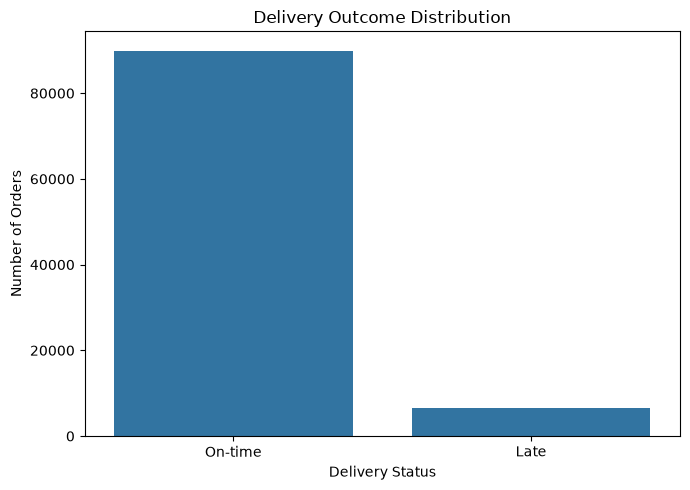

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=delivered_orders, x='delivery_status')

plt.title('Delivery Outcome Distribution')
plt.xlabel('Delivery Status')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

3. EDA ka next step — Delay days distribution
Abhi humne binary classes bana li hain, lekin actual delay days ka distribution bhi dekhna important hai.

Ye graph batayega:
- Orders kitne days early deliver ho rahe hain.
- Delivery date ke aas-paas kitne orders hain.
- Late orders ka spread kaisa hai.
- Extreme delays/outliers kitne hain.

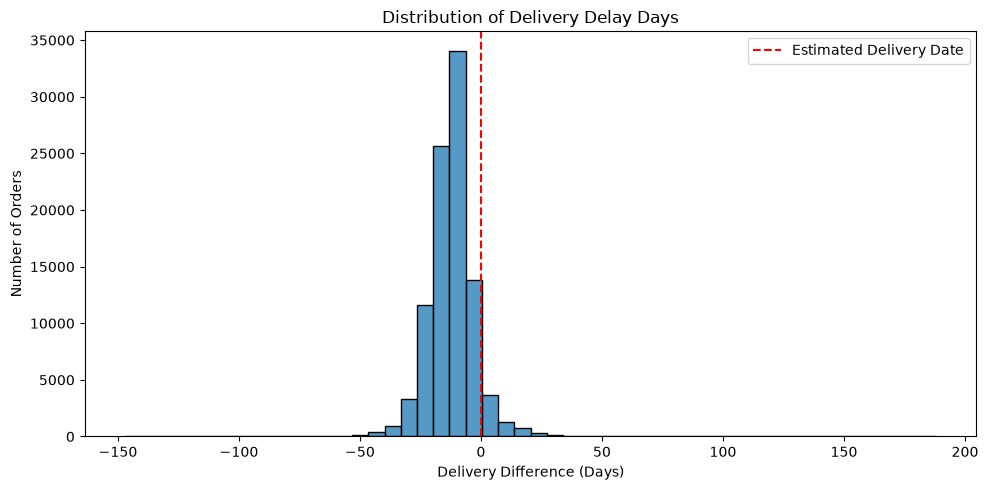

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=delivered_orders,
    x='delivery_delay_days',
    bins=50
)

plt.axvline(0, color='red', linestyle='--', label='Estimated Delivery Date')

plt.title('Distribution of Delivery Delay Days')
plt.xlabel('Delivery Difference (Days)')
plt.ylabel('Number of Orders')
plt.legend()

plt.tight_layout()
plt.show()

Tumhare graph mein:
- Most deliveries estimated delivery date se pehle hui hain (negative delay days).
- Sabse zyada observations roughly −15 se −5 days ke range mein concentrated hain.
- 0 ke paas distribution estimated delivery date ko represent karta hai.
- Zero ke right side positive values late deliveries represent karti hain.
- Distribution right-skewed hai, kyunki kuch orders ka delay kaafi zyada hai.
- Extreme values around −147 days aur +188 days bhi hain, jo further investigation deserve karti hain.
2. Ek important observation — outliers
Tumhare previous statistics mein:
- Minimum = −147 days
- Maximum = +188 days
- Median = −12 days
Ye extreme values normal delivery pattern se kaafi different hain. Lekin abhi inhe remove nahi karna hai. Pehle inspect karenge ki ye genuine orders hain, unusual cases hain, ya data quality issues.

3. Next step: Extreme deliveries investigate karo
A. Sabse late delivered orders

sabse jaldi

In [ ]:
delivered_orders.sort_values(
    'delivery_delay_days',
    ascending=True
)[[
    'order_id',
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'delivery_delay_days'
]].head(10)

,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days
40094,0607f0efea4b566f1eb8f7d3c2397320,2018-03-06 09:47:07,2018-03-09 23:36:47,2018-08-03,-147
15791,c72727d29cde4cf870d569bf65edabfd,2017-02-07 18:01:15,2017-02-14 14:27:45,2017-07-04,-140
57160,eec7f369423b033e549c02f3c5381205,2018-02-06 20:44:56,2018-02-27 16:35:43,2018-07-12,-135
86444,c2bb89b5c1dd978d507284be78a04cb2,2017-05-23 22:28:36,2017-06-09 13:35:54,2017-10-11,-124
67488,40dc2ba6f322a17626aac6244332828c,2017-10-05 21:39:05,2017-10-13 13:49:07,2018-01-30,-109
79449,1a695d543b7302aa9446c8d5fbd632bf,2017-12-16 10:32:49,2017-12-28 22:18:23,2018-03-22,-84
62706,39e0115911bf404857e14baa7f097feb,2018-01-20 07:48:16,2018-02-01 01:52:34,2018-04-25,-83
37491,c5132855100a12d63ed4e8ae05f9594d,2017-10-13 14:45:03,2017-10-25 20:22:10,2018-01-11,-78
63537,38930f76efb00b138f4d632e4d557341,2018-01-28 13:47:42,2018-02-08 19:21:39,2018-04-27,-78
95849,559eea5a72341a4c82dbce9884277cb7,2017-11-17 10:24:03,2017-11-30 16:12:50,2018-02-16,-78


In [ ]:
delivered_orders.sort_values(
    'delivery_delay_days',
    ascending=False
)[[
    'order_id',
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'delivery_delay_days'
]].head(10)

,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,188
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22,181
11399,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19,175
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05,167
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,166
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-09-19 15:12:50,2017-04-07,165
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:17,2017-09-19 17:14:25,2017-04-10,162
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-09-19 14:38:21,2017-04-11,161
40847,d24e8541128cea179a11a65176e0a96f,2017-06-12 13:14:11,2017-12-04 18:36:29,2017-06-26,161
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:27,2017-09-19 14:38:18,2017-04-13,159


In [ ]:
delivered_orders['actual_delivery_days'] = (
    delivered_orders['order_delivered_customer_date'] -
    delivered_orders['order_purchase_timestamp']
).dt.total_seconds() / (24 * 60 * 60)

delivered_orders['estimated_delivery_days'] = (
    delivered_orders['order_estimated_delivery_date'] -
    delivered_orders['order_purchase_timestamp']
).dt.total_seconds() / (24 * 60 * 60)

delivered_orders[
    [
        'order_purchase_timestamp',
        'order_delivered_customer_date',
        'order_estimated_delivery_date',
        'actual_delivery_days',
        'estimated_delivery_days',
        'delivery_delay_days'
    ]
].sort_values('delivery_delay_days').head(10)

,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,actual_delivery_days,estimated_delivery_days,delivery_delay_days
40094,2018-03-06 09:47:07,2018-03-09 23:36:47,2018-08-03,3.576157,149.592280,-147
15791,2017-02-07 18:01:15,2017-02-14 14:27:45,2017-07-04,6.851736,146.249132,-140
57160,2018-02-06 20:44:56,2018-02-27 16:35:43,2018-07-12,20.826933,155.135463,-135
86444,2017-05-23 22:28:36,2017-06-09 13:35:54,2017-10-11,16.630069,140.063472,-124
67488,2017-10-05 21:39:05,2017-10-13 13:49:07,2018-01-30,7.673634,116.097859,-109
79449,2017-12-16 10:32:49,2017-12-28 22:18:23,2018-03-22,12.489977,95.560544,-84
62706,2018-01-20 07:48:16,2018-02-01 01:52:34,2018-04-25,11.752986,94.674815,-83
37491,2017-10-13 14:45:03,2017-10-25 20:22:10,2018-01-11,12.234109,89.385382,-78
63537,2018-01-28 13:47:42,2018-02-08 19:21:39,2018-04-27,11.231910,88.425208,-78
95849,2017-11-17 10:24:03,2017-11-30 16:12:50,2018-02-16,13.242211,90.566632,-78


Isse kya samajh aayega?
Hum verify karenge ki:
- Actual delivery kitne days leti hai?
- Estimated delivery kitne days ahead predict ki gayi thi?
- Extreme negative delay estimate ki wajah se hai ya actual delivery behavior ki wajah se?
Abhi outliers delete nahi karna. Pehle investigate karna, phir evidence ke basis par treatment decide karna—ye proper Data Science approach hai.

### Outlier Investigation — Delivery Delay

Extreme negative delivery delay records were investigated by comparing actual delivery duration with the estimated delivery duration.

The investigation revealed that several orders were delivered within approximately 3–21 days, while their estimated delivery windows were unusually long (approximately 89–155 days).

These records indicate that extreme negative delay values are largely associated with unusually distant estimated delivery dates rather than exceptionally fast delivery alone.

**Decision:** Extreme values are not removed at this stage. Further investigation will be performed before deciding on outlier treatment.

4. Ab next step
Ab hum actual delivery time distribution analyze karenge. Ye delay distribution se different hai.

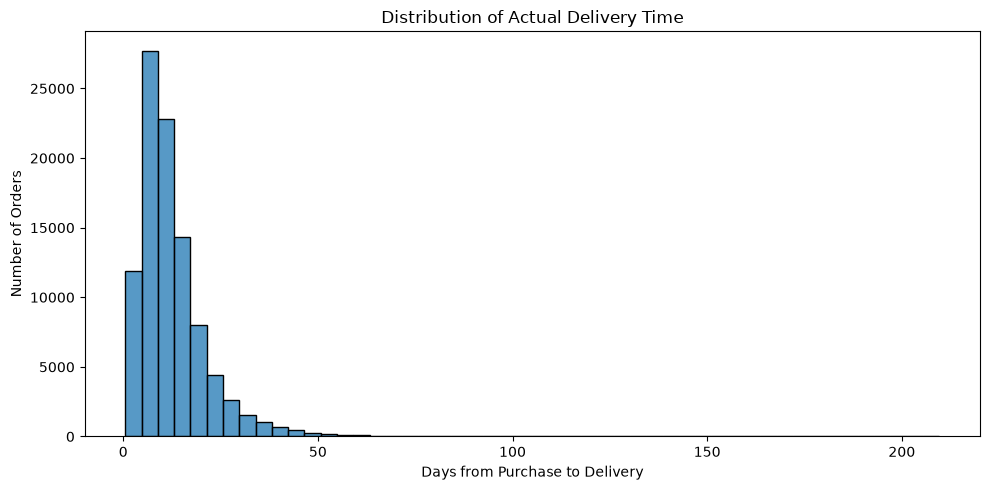

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=delivered_orders,
    x='actual_delivery_days',
    bins=50
)

plt.title('Distribution of Actual Delivery Time')
plt.xlabel('Days from Purchase to Delivery')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

In [ ]:
delivered_orders['actual_delivery_days'].describe().round(2)

count    96470.00
mean        12.56
std          9.55
min          0.53
25%          6.77
50%         10.22
75%         15.72
max        209.63
Name: actual_delivery_days, dtype: float64

In [ ]:
delivered_orders['actual_delivery_days'].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
).round(2)

0.50    10.22
0.75    15.72
0.90    23.10
0.95    29.27
0.99    46.05
Name: actual_delivery_days, dtype: float64

### Actual Delivery Time — Percentile Analysis

The actual delivery time analysis shows that 50% of orders were delivered within approximately 10.22 days, while 75% were delivered within 15.72 days.

The 90th percentile is 23.10 days, the 95th percentile is 29.27 days, and the 99th percentile is 46.05 days.

**Key Insight:** Most orders are delivered within a relatively short time, but a long tail of slow deliveries exists. This indicates variability in delivery performance and highlights the importance of identifying factors associated with delayed shipments.

Geographical Analysis start karte hain. Ye tumhare Smart Logistics Delay Prediction project ka important phase hoga, kyunki hume investigate karna hai ki customer aur seller ki location delivery performance ko kaise affect karti hai.

Lekin sabse pehle datasets ke relationships samjhenge. Direct merge nahi karenge.
Step 1 — Customer, Seller aur Order Items datasets load karo
Tumhare data/raw folder mein ye files already hain.

In [ ]:
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")

sellers = pd.read_csv("../data/raw/olist_sellers_dataset.csv")

order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")

In [ ]:
print("Customers Shape:", customers.shape)
print("Sellers Shape:", sellers.shape)
print("Order Items Shape:", order_items.shape)

Customers Shape: (99441, 5)
Sellers Shape: (3095, 4)
Order Items Shape: (112650, 7)


In [ ]:
print("Customer Columns:")
print(customers.columns.tolist())

print("\nSeller Columns:")
print(sellers.columns.tolist())

print("\nOrder Items Columns:")
print(order_items.columns.tolist())

Customer Columns:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Seller Columns:
['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

Order Items Columns:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']


Ek important concept:

Ek order mein multiple products aur multiple sellers ho sakte hain. Isliye:
- Orders → Customers: One-to-One relationship (dataset mein customer ke multiple orders ho sakte hain, so logically one-to-many).
- Orders → Order Items: One-to-Many.
- Order Items → Sellers: Many-to-One.
Agar hum directly orders ko order_items ke saath merge karenge, toh ek order multiple rows mein aa sakta hai. Isliye order-level analysis mein aggregation zaroori hogi.

Step 4 — Primary keys aur duplicates verify karo

In [ ]:
print("Customer ID duplicates:", customers['customer_id'].duplicated().sum())

print("Seller ID duplicates:", sellers['seller_id'].duplicated().sum())

print("Order ID duplicates:", orders['order_id'].duplicated().sum())

print("Order Items null seller IDs:", order_items['seller_id'].isnull().sum())

Customer ID duplicates: 0
Seller ID duplicates: 0
Order ID duplicates: 0
Order Items null seller IDs: 0


Step 5 — Delivered orders mein customer location merge karo
Hum delivered_orders ko customers ke saath merge karenge.

In [ ]:
customer_delivery = delivered_orders.merge(
    customers[['customer_id', 'customer_state', 'customer_city']],
    on='customer_id',
    how='left',
    validate='many_to_one'
)

validate='many_to_one' kyun use kiya?
- Orders mein ek customer multiple orders kar sakta hai.
- Customers dataset mein har customer_id unique hai.
- Ye validation ensure karega ki merge ka relationship expected hai.
- Agar relationship unexpected hua, Pandas error dega, jo data integrity issue detect karne mein help karega.

In [ ]:
print("Before merge:", delivered_orders.shape)
print("After merge:", customer_delivery.shape)

print(
    "Missing customer states:",
    customer_delivery['customer_state'].isnull().sum()
)

Before merge: (96470, 12)
After merge: (96470, 14)
Missing customer states: 0


Step 7 — State-wise delivery performance
Ab state-wise analyze karenge:
- Kitne orders deliver hue?
- Average delivery time kitna hai?
- Late delivery percentage kitni hai?

In [ ]:
customer_state_analysis = customer_delivery.groupby('customer_state').agg(
    total_orders=('order_id', 'count'),
    avg_delivery_days=('actual_delivery_days', 'mean'),
    late_orders=('delivery_status', lambda x: (x == 'Late').sum()),
    late_percentage=('delivery_status', lambda x: (x == 'Late').mean() * 100)
).sort_values('late_percentage', ascending=False)

customer_state_analysis.round(2)

,total_orders,avg_delivery_days,late_orders,late_percentage
customer_state,,,,
AL,397,24.54,85,21.41
MA,717,21.57,125,17.43
SE,335,21.52,51,15.22
PI,476,19.46,66,13.87
CE,1279,21.27,176,13.76
RR,41,29.39,5,12.20
BA,3256,19.34,396,12.16
RJ,12350,15.31,1495,12.11
PA,946,23.77,106,11.21


Step 8 — Visualize late delivery percentage by state

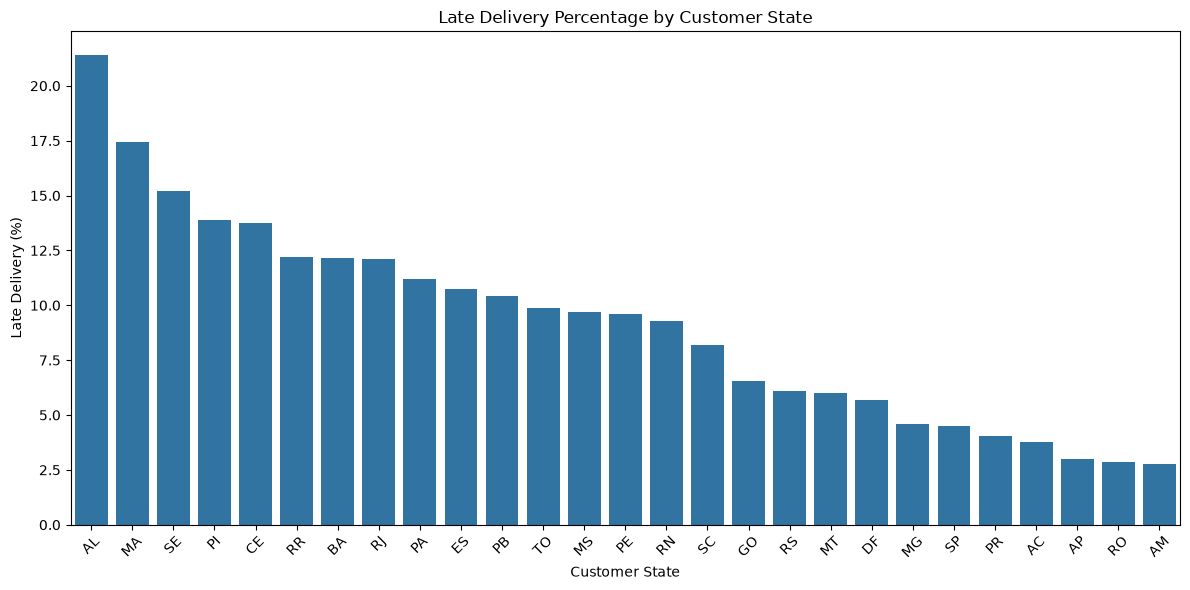

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=customer_state_analysis.reset_index(),
    x='customer_state',
    y='late_percentage'
)

plt.title('Late Delivery Percentage by Customer State')
plt.xlabel('Customer State')
plt.ylabel('Late Delivery (%)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Next step — order volume ke saath comparison

In [ ]:
customer_state_analysis.sort_values(
    'late_percentage',
    ascending=False
).round(2)

,total_orders,avg_delivery_days,late_orders,late_percentage
customer_state,,,,
AL,397,24.54,85,21.41
MA,717,21.57,125,17.43
SE,335,21.52,51,15.22
PI,476,19.46,66,13.87
CE,1279,21.27,176,13.76
RR,41,29.39,5,12.20
BA,3256,19.34,396,12.16
RJ,12350,15.31,1495,12.11
PA,946,23.77,106,11.21


Phir low-volume states filter karenge

In [ ]:
state_filtered = customer_state_analysis[
    customer_state_analysis['total_orders'] >= 100
].sort_values('late_percentage', ascending=False)

state_filtered.round(2)

,total_orders,avg_delivery_days,late_orders,late_percentage
customer_state,,,,
AL,397,24.54,85,21.41
MA,717,21.57,125,17.43
SE,335,21.52,51,15.22
PI,476,19.46,66,13.87
CE,1279,21.27,176,13.76
BA,3256,19.34,396,12.16
RJ,12350,15.31,1495,12.11
PA,946,23.77,106,11.21
ES,1995,15.79,214,10.73


### Customer State-wise Delivery Analysis

Customer state-wise analysis revealed considerable variation in late-delivery rates across geographical regions.

AL recorded the highest late-delivery percentage at 21.41%, followed by MA at 17.43% and SE at 15.22%. In contrast, SP had a late-delivery rate of 4.49% despite having the largest order volume and the highest number of late orders (1,820).

The analysis highlights that delivery performance differs across customer destinations. Both late-delivery percentage and order volume should be considered when evaluating geographical logistics performance.

**Conclusion:** Customer state may provide useful geographical information for delay prediction. However, state-wise differences are observational and do not establish causation.

Step 1 — Seller data ko orders ke saath connect karna
Hume 3 datasets ka relationship use karna hoga:
- delivered_orders → delivery outcome, actual delivery time
- order_items → kis order mein kaun sa seller tha
- sellers → seller ki location/state
Relationship:

In [ ]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [ ]:
order_items.groupby('order_id')['seller_id'].nunique().sort_values(ascending=False).head(10)

order_id
1c11d0f4353b31ac3417fbfa5f0f2a8a    5
cf5c8d9f52807cb2d2f0a0ff54c478da    5
91be51c856a90d7efe86cf9d082d6ae3    4
1d23106803c48c391366ff224513fb7f    4
8c2b13adf3f377c8f2b06b04321b0925    4
76c4c846aae2dae9e87dfa492c3f5259    3
780dfcd5aaf2662f3f6ce2201164394b    3
14f0429b74bbb862693e5a88af6f6f6a    3
338ffe54b65a3b8124c81ebe6d1cc4b0    3
34fdc362961364d3ff08986ccff2212d    3
Name: seller_id, dtype: int64

In [ ]:
order_items.groupby('order_id')['seller_id'].nunique().sort_values(ascending=False).head(10)

order_id
1c11d0f4353b31ac3417fbfa5f0f2a8a    5
cf5c8d9f52807cb2d2f0a0ff54c478da    5
91be51c856a90d7efe86cf9d082d6ae3    4
1d23106803c48c391366ff224513fb7f    4
8c2b13adf3f377c8f2b06b04321b0925    4
76c4c846aae2dae9e87dfa492c3f5259    3
780dfcd5aaf2662f3f6ce2201164394b    3
14f0429b74bbb862693e5a88af6f6f6a    3
338ffe54b65a3b8124c81ebe6d1cc4b0    3
34fdc362961364d3ff08986ccff2212d    3
Name: seller_id, dtype: int64

Step 1: Seller-state analysis ke liye merge
Ab hum delivered orders ko order items ke saath merge karenge, aur phir sellers ke data se seller state add karenge.

In [ ]:
seller_delivery = delivered_orders.merge(
    order_items[['order_id', 'seller_id', 'price', 'freight_value']],
    on='order_id',
    how='inner'
)

seller_delivery = seller_delivery.merge(
    sellers[['seller_id', 'seller_state']],
    on='seller_id',
    how='left'
)

delivered_orders → delivery ka result aur delay information.



order_items → order kis seller se fulfill hua.



sellers → seller kis state mein located hai.

In [ ]:
print("Shape:", seller_delivery.shape)

display(seller_delivery.head())

print("Missing seller states:", seller_delivery['seller_state'].isnull().sum())

Shape: (110189, 16)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days,delivery_status,actual_delivery_days,estimated_delivery_days,seller_id,price,freight_value,seller_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,-8,On-time,8.436574,15.544063,3504c0cb71d7fa48d967e0e4c94d59d9,29.99,8.72,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,-6,On-time,13.782037,19.137766,289cdb325fb7e7f891c38608bf9e0962,118.70,22.76,SP
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,-18,On-time,9.394213,26.639711,4869f7a5dfa277a7dca6462dcf3b52b2,159.90,19.22,SP
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,-13,On-time,13.208750,26.188819,66922902710d126a0e7d26b0e3805106,45.00,27.20,MG
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,-10,On-time,2.873877,12.112049,2c9e548be18521d1c43cde1c582c6de8,19.90,8.72,SP


Missing seller states: 0


Step 2 — Seller state-wise delivery performance

In [ ]:
seller_state_analysis = seller_delivery.groupby('seller_state').agg(
    total_orders=('order_id', 'nunique'),
    avg_delivery_days=('actual_delivery_days', 'mean'),
    late_orders=('delivery_status', lambda x: (x == 'Late').sum()),
    late_percentage=('delivery_status', lambda x: (x == 'Late').mean() * 100)
).sort_values('late_percentage', ascending=False)

display(seller_state_analysis.round(2))

,total_orders,avg_delivery_days,late_orders,late_percentage
seller_state,,,,
AM,3,47.84,1,33.33
MA,389,17.74,78,19.40
RN,51,13.02,4,7.14
SP,68635,12.28,5585,7.11
RJ,4227,12.02,324,6.92
CE,87,17.89,6,6.67
DF,808,12.53,53,6.00
MS,49,12.33,3,6.00
ES,310,12.88,21,5.77


1. Key observations
- AM (Amazonas) has 33.33% late rate, but only 3 orders — sample bahut chhota hai, isliye reliable conclusion nahi nikal sakte.
- MA (Maranhão) has 19.40% late rate with 389 orders — ye concerning performance hai, aur sample AM se kaafi better hai.
- SP (São Paulo) has 7.11% late rate but 68,635 orders — percentage moderate hai, lekin late items ki count 5,585 hai, jo sabse zyada hai.
- RJ (Rio de Janeiro) has 6.92% late rate and 4,227 orders.
- MG (Minas Gerais) has 4.79% late rate with 7,733 orders.
- RS has 3.23% late rate and 1,962 orders.

2. Graph — Seller State vs Late Delivery %
Low-volume states ki wajah se graph misleading ho sakta hai. Isliye pehle minimum 100 orders wale seller states include karenge.

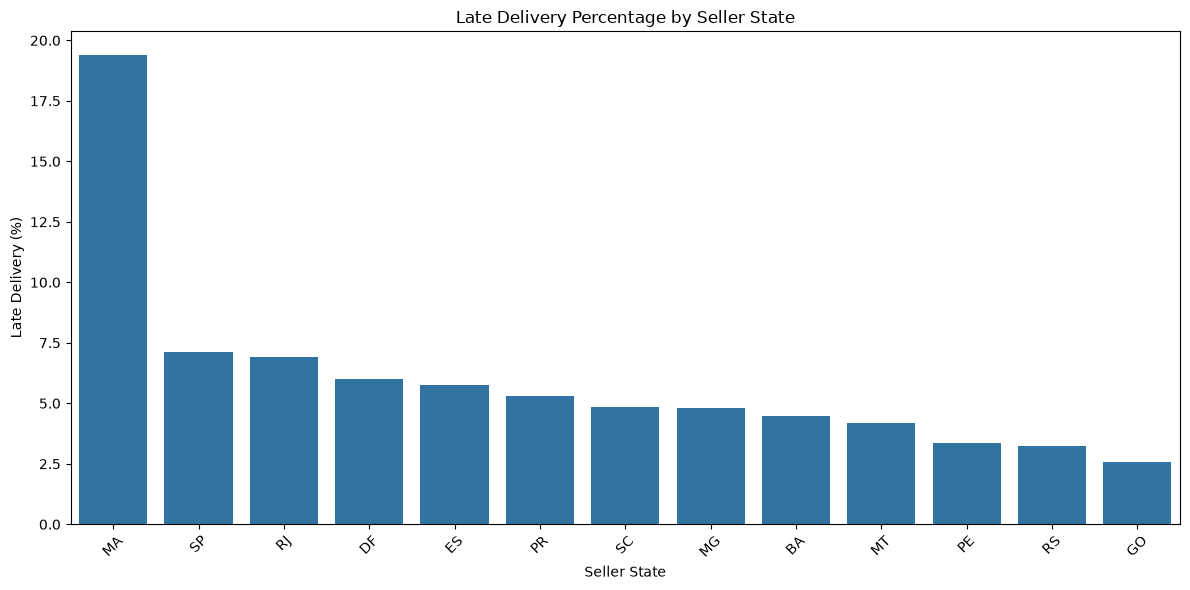

In [ ]:
seller_state_filtered = seller_state_analysis[
    seller_state_analysis['total_orders'] >= 100
].sort_values('late_percentage', ascending=False)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=seller_state_filtered.index,
    y=seller_state_filtered['late_percentage']
)

plt.title('Late Delivery Percentage by Seller State')
plt.xlabel('Seller State')
plt.ylabel('Late Delivery (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

3. Project finding
Notebook mein abhi ye finding likh sakti ho:
Seller-state analysis revealed variations in delivery outcomes across seller locations. Maranhão (MA) showed a comparatively high late-delivery rate (19.40%) among states with a meaningful order volume, while São Paulo (SP) contributed the highest number of late deliveries due to its significantly larger order volume. Results from low-volume states should be interpreted cautiously.

Ek analytical correction:

total_orders unique orders count karta hai, jabki late_orders aur late_percentage currently item-level rows par calculated hain. Ye denominators different hain. Hum final analysis se pehle is metric ko consistent banayenge, taaki project mein percentage aur counts mathematically comparable hon.

Seller-state analysis showed variation in late-delivery rates across seller locations. MA recorded the highest late-delivery rate (~19.4%) among the states with at least 100 unique orders. SP had a moderate late-delivery rate (~7.1%) but contributed the largest number of late deliveries due to its significantly higher order volume. This indicates that both delivery rate and order volume should be considered when evaluating logistics performance.

Seller-state analysis ka visualization complete hai.

Next, hum numerical analysis mein enter karenge—yahan hum distributions, outliers aur relationships explore karenge. Is stage mein boxplots, scatterplots, correlation matrix aur heatmap aayenge, aur ye sab model ke features select karne mein help karenge.

Step 1 — Numerical features identify karna
Sabse pehle check karte hain ki delivered_orders mein kaun-kaun se numerical columns available hain

In [ ]:
delivered_orders.select_dtypes(include='number').columns

Index(['delivery_delay_days', 'actual_delivery_days',
       'estimated_delivery_days'],
      dtype='str')

Ye code kya kar raha hai?
- select_dtypes(include='number') → DataFrame se sirf numeric data select karta hai (integer, float).
- .columns → un numeric columns ke names deta hai.
Hum ye isliye kar rahe hain taaki pata chale kaunse features par histogram, boxplot, correlation matrix aur heatmap apply karna meaningful hoga.

Step 2 — Numerical features ki distribution
Sabse pehle hum histograms banayenge, taaki dekhein data ka distribution kaisa hai, values kahan concentrated hain, aur skewness hai ya nahi.

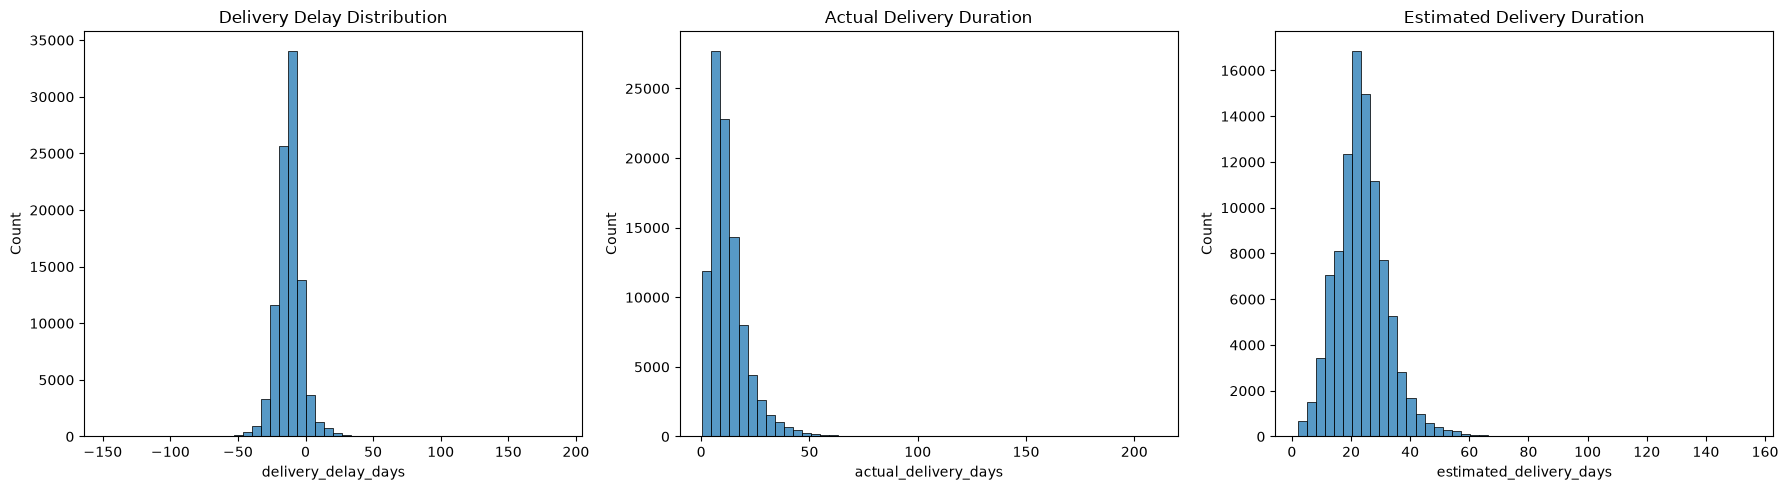

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(delivered_orders['delivery_delay_days'], bins=50, ax=axes[0])
axes[0].set_title('Delivery Delay Distribution')

sns.histplot(delivered_orders['actual_delivery_days'], bins=50, ax=axes[1])
axes[1].set_title('Actual Delivery Duration')

sns.histplot(delivered_orders['estimated_delivery_days'], bins=50, ax=axes[2])
axes[2].set_title('Estimated Delivery Duration')

plt.tight_layout()
plt.show()

Step 1: Distribution interpretation
1. Delivery Delay Distribution
- Most values 0 se kam hain, iska matlab majority orders estimated delivery date se pehle pahunch rahe hain.
- Values roughly −15 to −5 days ke around concentrated hain.
- Distribution mein positive tail bhi hai, yani kuch orders kaafi late deliver hue.
- Distribution mein extreme values bhi hain.
2. Actual Delivery Duration
- Majority deliveries roughly 5–20 days ke beech complete ho rahi hain.
- Distribution right-skewed hai.
- Kuch deliveries mein 30, 50 ya usse bhi zyada days lage hain.
- Long tail indicate karti hai ki kuch orders unusually slow the.
3. Estimated Delivery Duration
- Estimated delivery duration mostly roughly 15–35 days ke around concentrated hai.
- Isme bhi right-skewed distribution hai.
- Kuch orders ke estimated durations unusually high hain.
- Long estimates logistics planning, destination, seller-side factors ya data quality se related ho sakte hain; further analysis ki zarurat hai.

### Numerical Feature Distribution Analysis

The delivery delay distribution is concentrated mostly in negative values, indicating that the majority of orders were delivered before their estimated delivery dates. However, a long tail toward positive values indicates late deliveries.

Actual delivery duration is right-skewed, with most orders delivered within approximately 5–20 days, while a small number of orders take significantly longer.

Estimated delivery duration also shows a right-skewed distribution, with most estimates concentrated between approximately 15 and 35 days and a few unusually large values.

These distributions indicate the presence of extreme observations and non-normal numerical features, which will be investigated further using boxplots and statistical analysis.

Step 3 — Boxplot interpretation
1. Delivery delay days
- Median approximately −12 days.
- Box (IQR) relatively compact hai, matlab most orders ka delivery delay range similar hai.
- Negative side mein extreme values (around −147 days) hain.
- Positive side mein bhi bahut saare outliers hain, jo severely late deliveries represent karte hain.
2. Actual delivery days
- Most deliveries box ke according approximately 5–16 days ke range mein hain.
- Median around 10 days.
- Upper side par large number of outliers hain.
- Kuch deliveries 100–200+ days tak ja rahi hain.
3. Estimated delivery days
- Most estimated duration approximately 18–29 days ke range mein hai.
- Upper side outliers kaafi hain.
- Kuch estimated delivery durations 100+ days tak hain, including very extreme values.
Step 4 — Outliers quantify karte hain
Abhi graph se outliers dikh rahe hain, lekin hum quantify bhi karenge ki kitne outliers hain aur kis threshold ke beyond hain.

Boxplot commonly IQR method use karta hai:
- \(Q1\) = 25th percentile
- \(Q3\) = 75th percentile
- \(IQR = Q3 - Q1\)
- Lower limit = \(Q1 - 1.5 \times IQR\)
- Upper limit = \(Q3 + 1.5 \times IQR\)

In [ ]:
numerical_cols = [
    'delivery_delay_days',
    'actual_delivery_days',
    'estimated_delivery_days'
]

for col in numerical_cols:
    Q1 = delivered_orders[col].quantile(0.25)
    Q3 = delivered_orders[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = delivered_orders[
        (delivered_orders[col] < lower_limit) |
        (delivered_orders[col] > upper_limit)
    ]

    print(f"\nFeature: {col}")
    print(f"Lower Limit: {lower_limit:.2f}")
    print(f"Upper Limit: {upper_limit:.2f}")
    print(f"Outliers: {len(outliers)}")
    print(f"Outlier Percentage: {len(outliers)/len(delivered_orders)*100:.2f}%")


Feature: delivery_delay_days
Lower Limit: -32.00
Upper Limit: 8.00
Outliers: 4297
Outlier Percentage: 4.45%

Feature: actual_delivery_days
Lower Limit: -6.66
Upper Limit: 29.15
Outliers: 4896
Outlier Percentage: 5.08%

Feature: estimated_delivery_days
Lower Limit: 3.21
Upper Limit: 43.52
Outliers: 2427
Outlier Percentage: 2.52%


longest delivery

In [ ]:
delivered_orders.nlargest(
    10, 'actual_delivery_days'
)[[
    'order_id',
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'actual_delivery_days',
    'estimated_delivery_days',
    'delivery_delay_days'
]]

,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,actual_delivery_days,estimated_delivery_days,delivery_delay_days
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22,209.628611,28.019826,181
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,208.351759,19.376678,188
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-09-19 15:12:50,2017-04-07,195.634016,30.000104,165
70307,2fb597c2f772eca01b1f5c561bf6cc7b,2017-03-08 18:09:02,2017-09-19 14:33:17,2017-04-17,194.850174,39.243727,155
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,194.633611,28.050231,166
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-09-19 14:38:21,2017-04-11,194.049583,32.439618,161
11399,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19,191.463542,15.594433,175
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05,189.863160,22.154745,167
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:27,2017-09-19 14:38:18,2017-04-13,188.134618,28.524687,159
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:17,2017-09-19 17:14:25,2017-04-10,187.743843,25.025498,162


Top 10 longest deliveries mein:
- Actual delivery duration: approximately 187–210 days
- Estimated delivery duration: approximately 15–39 days
- Delay: approximately 155–188 days
- Actual delivered dates repeatedly September 2017 aur September 2018 ke around aa rahi hain.
Kuch records mein purchase February/March mein hui, lekin delivery September mein record hui. Ye unusually long delivery durations hain.

Isse potential data anomaly ya unusual delivery records ka suspicion hota hai, lekin abhi ye confirm nahi karenge ki incorrect data hai. Pehle verify karenge ki September 19 ko delivery dates unusually zyada record hui hain ya nahi.
Next step — Delivery date anomaly verify karna

In [ ]:
delivered_orders['order_delivered_customer_date'].dt.date.value_counts().head(10)

order_delivered_customer_date
2018-08-27    446
2018-08-13    442
2018-05-14    434
2018-05-21    431
2018-05-18    425
2018-04-11    413
2017-12-11    412
2018-07-03    410
2018-05-03    409
2018-07-30    405
Name: count, dtype: int64

In [ ]:
delivered_orders[
    delivered_orders['order_delivered_customer_date'].dt.strftime('%m-%d') == '09-19'
]['order_delivered_customer_date'].dt.date.value_counts().sort_index()

order_delivered_customer_date
2017-09-19    282
2018-09-19      3
Name: count, dtype: int64

In [ ]:
delivered_orders[
    delivered_orders['order_delivered_customer_date'].dt.date == pd.to_datetime('2017-09-19').date()
][[
    'order_id',
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'actual_delivery_days',
    'estimated_delivery_days',
    'delivery_delay_days'
]].sort_values('actual_delivery_days', ascending=False).head(10)

,order_id,order_purchase_timestamp,order_delivered_customer_date,actual_delivery_days,estimated_delivery_days,delivery_delay_days
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:27,2017-09-19 14:36:39,209.628611,28.019826,181
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-09-19 15:12:50,195.634016,30.000104,165
70307,2fb597c2f772eca01b1f5c561bf6cc7b,2017-03-08 18:09:02,2017-09-19 14:33:17,194.850174,39.243727,155
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-09-19 14:00:04,194.633611,28.050231,166
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-09-19 14:38:21,194.049583,32.439618,161
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:10,2017-09-19 17:00:07,189.863160,22.154745,167
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:27,2017-09-19 14:38:18,188.134618,28.524687,159
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:17,2017-09-19 17:14:25,187.743843,25.025498,162
62286,437222e3fd1b07396f1d9ba8c15fba59,2017-03-16 11:36:00,2017-09-19 16:28:58,187.203449,42.516667,144
31228,dfe5f68118c2576143240b8d78e5940a,2017-03-17 12:32:22,2017-09-19 18:13:19,186.236771,32.477523,153


Notebook mein ye finding add kar lo:
During outlier investigation, several orders purchased between February and March 2017 were found to have the same customer delivery date (September 19, 2017). These records showed actual delivery durations of approximately 186–210 days, despite estimated delivery durations of around 22–43 days. This repeated date pattern suggests potential data-recording anomalies or exceptional delivery cases. These records are flagged for further investigation rather than removed immediately.

In [ ]:
sep19_deliveries = delivered_orders[
    delivered_orders['order_delivered_customer_date'].dt.date 
    == pd.to_datetime('2017-09-19').date()
]

sep19_deliveries['actual_delivery_days'].describe()

count    282.000000
mean      27.670927
std       44.235632
min        1.137141
25%        7.858556
50%       11.802679
75%       21.584864
max      209.628611
Name: actual_delivery_days, dtype: float64

In [ ]:
(sep19_deliveries['actual_delivery_days'] > 90).sum()

np.int64(24)

In [ ]:
sep19_deliveries[
    sep19_deliveries['actual_delivery_days'] > 90
][[
    'order_id',
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'actual_delivery_days',
    'estimated_delivery_days',
    'delivery_delay_days'
]].sort_values('actual_delivery_days', ascending=False)

,order_id,order_purchase_timestamp,order_delivered_customer_date,actual_delivery_days,estimated_delivery_days,delivery_delay_days
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:27,2017-09-19 14:36:39,209.628611,28.019826,181
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-09-19 15:12:50,195.634016,30.000104,165
70307,2fb597c2f772eca01b1f5c561bf6cc7b,2017-03-08 18:09:02,2017-09-19 14:33:17,194.850174,39.243727,155
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-09-19 14:00:04,194.633611,28.050231,166
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-09-19 14:38:21,194.049583,32.439618,161
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:10,2017-09-19 17:00:07,189.863160,22.154745,167
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:27,2017-09-19 14:38:18,188.134618,28.524687,159
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:17,2017-09-19 17:14:25,187.743843,25.025498,162
62286,437222e3fd1b07396f1d9ba8c15fba59,2017-03-16 11:36:00,2017-09-19 16:28:58,187.203449,42.516667,144
31228,dfe5f68118c2576143240b8d78e5940a,2017-03-17 12:32:22,2017-09-19 18:13:19,186.236771,32.477523,153


In [ ]:
sep19_deliveries[
    sep19_deliveries['actual_delivery_days'] > 90
][[
    'order_purchase_timestamp',
    'actual_delivery_days',
    'estimated_delivery_days',
    'delivery_delay_days'
]].sort_values(
    'actual_delivery_days', ascending=False
).head(5)

,order_purchase_timestamp,actual_delivery_days,estimated_delivery_days,delivery_delay_days
19590,2017-02-21 23:31:27,209.628611,28.019826,181
61610,2017-03-07 23:59:51,195.634016,30.000104,165
70307,2017-03-08 18:09:02,194.850174,39.243727,155
89130,2017-03-08 22:47:40,194.633611,28.050231,166
38509,2017-03-09 13:26:57,194.049583,32.439618,161


19 September 2017 ko record hui, jiski wajah se actual delivery duration 194–210 days ho gayi.

Ab hum is investigation se ye conclude kar sakte hain:
- 19 September ko delivered hue 282 orders mein 24 orders ka actual duration 90 days se zyada tha (~8.51%).
- Ye 5 examples extremely long deliveries show karte hain.
- Ye extreme observations overall delivery-duration distribution ko right-skew kar rahe hain.
- Possible date-recording anomaly hai, but root cause confirm nahi hai.
Outlier investigation — completed ✅
Abhi hum outliers remove nahi karenge. Reason:
- Ye real extreme delivery cases bhi ho sakte hain.
- Date anomaly ka evidence mila, but data error conclusively prove nahi hua.
- Prediction model ko real-world difficult deliveries bhi learn karni chahiye.
Notebook mein outlier investigation ka conclusion add kar lo.

Feature relationships & correlation analysis
Abhi numerical columns sirf 3 hain. Meaningful correlation matrix aur heatmap banane ke liye hume dataset se aur numerical features nikalne honge.

Step 1 — Order-level numerical features

In [ ]:
order_features = order_items.groupby('order_id').agg(
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    item_count=('order_item_id', 'count')
).reset_index()

order_features.head()

,order_id,total_price,total_freight,item_count
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,1
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,1
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,1
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,1


Step 2 — Verify aggregation
Ab check karte hain ki multi-item orders bhi properly aggregate hue hain ya nahi.

In [ ]:
order_features['item_count'].value_counts().sort_index()

item_count
1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
11        4
12        5
13        1
14        2
15        2
20        2
21        1
Name: count, dtype: int64

- Most orders (around 89%) contain a single item.
- Around 7.5% orders contain 2 items.
- Very few orders have more than 5 items.
- Maximum item count is 21.
Isliye item_count ek useful numerical feature ho sakta hai — kyunki multi-item orders ki packing aur shipping complexity single-item orders se different ho sakti hai, aur delivery delay ke saath relationship investigate kar sakte hain.
2. Ab ek visualization banate hain
Abhi ek simple bar chart banayenge, taaki item count distribution visually clear ho. Rare item counts ko bhi dikhayenge, lekin graph readable rakhne ke liye 7+ category combine karenge.

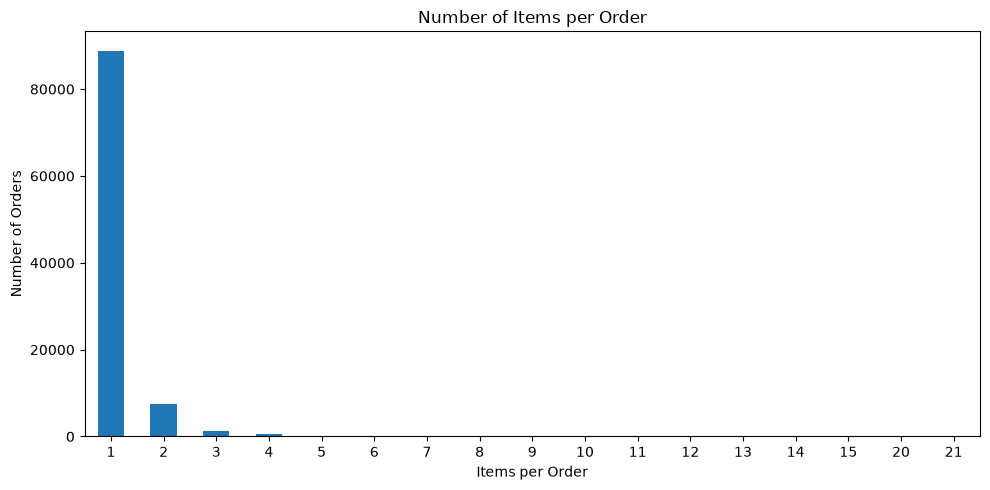

In [ ]:
item_distribution = order_features['item_count'].value_counts().sort_index()

item_distribution_grouped = item_distribution.copy()
item_distribution_grouped.loc[7:] = item_distribution_grouped.loc[7:].sum()

plt.figure(figsize=(10, 5))
item_distribution_grouped.plot(kind='bar')

plt.title('Number of Items per Order')
plt.xlabel('Items per Order')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Graph se kya samajh aaya?
- 1 item: sabse zyada orders — 88,863 (approximately 89%)
- 2 items: 7,516 orders
- 3 items: 1,322 orders
- 4+ items: orders ka count rapidly decrease ho raha hai.
- Maximum 21 items ek order mein mile hain.
Distribution highly right-skewed hai. Majority orders mein ek item hai, aur very few orders mein multiple items hain.
Notebook finding
The item count distribution is highly right-skewed, with approximately 89% of orders containing a single item. Orders with multiple items are relatively uncommon, and only a small proportion contain more than four items. Item count may be a useful feature for analyzing the relationship between order complexity and delivery delays.

Next step: Numerical features ko main dataset mein merge karna
Ab hum total_price, total_freight aur item_count ko delivered_orders ke saath combine karenge.

Ek hi order ki ek row rahegi, kyunki order_features already order-level par aggregated hai.

In [ ]:
delivery_data = delivered_orders.merge(
    order_features,
    on='order_id',
    how='left'
)

delivery_data.shape

(96470, 15)

In [ ]:
delivery_data[['total_price', 'total_freight', 'item_count']].isnull().sum()

total_price      0
total_freight    0
item_count       0
dtype: int64

Next step — Numerical feature distribution
Ab hum total_price se start karenge. Isse samjhenge ki order value ka distribution kaisa hai, typical order value kya hai, aur high-value orders kitne hain.
Cell 1 — Descriptive statistics

In [ ]:
delivery_data['total_price'].describe()

count    96470.000000
mean       137.040001
std        209.052608
min          0.850000
25%         45.900000
50%         86.500000
75%        149.900000
max      13440.000000
Name: total_price, dtype: float64

2. Distribution visualize karte hain
Ab histogram banayenge taaki dekhein order values kis range mein concentrated hain aur high-value orders distribution ko kitna skew kar rahe hain.

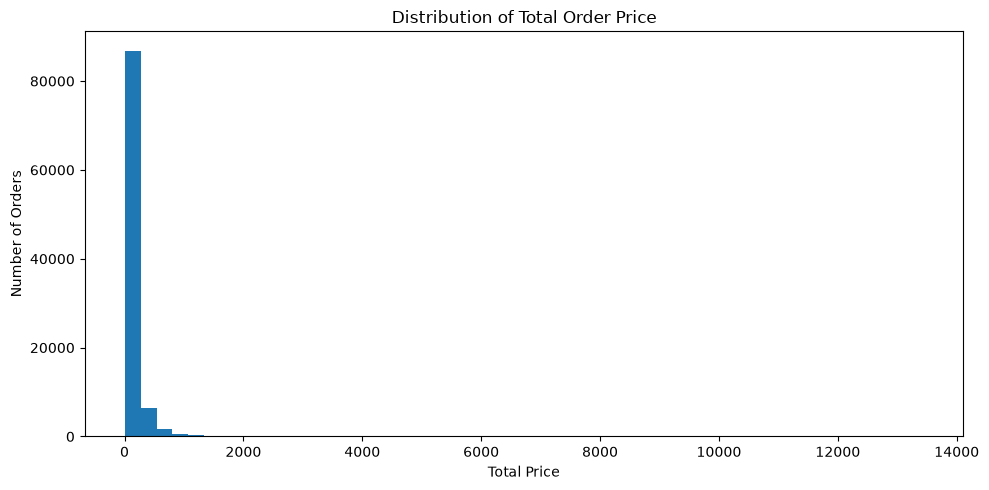

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(delivery_data['total_price'], bins=50)

plt.title('Distribution of Total Order Price')
plt.xlabel('Total Price')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

Graph clearly right-skewed hai. 👍
1. Graph interpretation
- Most orders ki price low range mein concentrated hai.
- Order price increase hone ke saath orders ki frequency rapidly decrease ho rahi hai.
- Kuch high-value orders right side mein long tail create kar rahe hain.
- Maximum order value ₹13,440 hai, jo typical orders se kaafi high hai.
Isliye distribution normal distribution nahi hai; it is highly positively (right) skewed.
2. Ye skewness modeling mein kyun important hai?
High-value orders kuch numerical features ko influence kar sakte hain:
- Mean median se kaafi higher hai.
- Standard deviation high hai.
- Outliers model ko influence kar sakte hain, especially Logistic Regression jaise models mein, jab scaling use hoti hai.
Lekin high-value orders automatically errors nahi hain. Ye genuine large purchases bhi ho sakti hain, isliye abhi remove nahi karenge.
3. Notebook finding
The total order price distribution is highly right-skewed. Most orders have relatively low monetary values, while a small number of high-value orders create a long right tail. The mean order value (137.04) is considerably higher than the median (86.50), indicating the influence of high-value orders. These observations suggest the presence of extreme values, which will be investigated further before deciding on any treatment.

Next step — Freight cost
Ab exactly same analysis total_freight par karenge. Freight delivery logistics ke liye important feature hai, aur hum investigate karenge ki freight cost mein kitna variation hai.

Pehle statistics:

In [ ]:
delivery_data['total_freight'].describe()

count    96470.000000
mean        22.785798
std         21.559959
min          0.000000
25%         13.850000
50%         17.170000
75%         24.020000
max       1794.960000
Name: total_freight, dtype: float64

1. Statistical interpretation
Metric	Value	Meaning
Count	96,470	Orders
Mean	22.79	Average freight cost
Std	21.56	Freight cost mein variation
Min	0.00	Kuch orders mein freight zero hai
25%	13.85	25% orders ka freight isse kam
Median	17.17	Typical freight cost
75%	24.02	75% orders is value tak
Max	1,794.96	Extremely high freight value

Important observations
- Mean (22.79), median (17.17) se higher hai — distribution right-skewed hone ka indication hai.
- Maximum 1,794.96, normal freight values ke comparison mein kaafi high hai.
- std = 21.56 bhi variation show karta hai, lekin extreme values isko influence kar sakti hain.
- Minimum zero hai, hume baad mein verify karna hoga ki zero freight valid orders hain ya data anomaly.
2. Freight distribution visualize karo

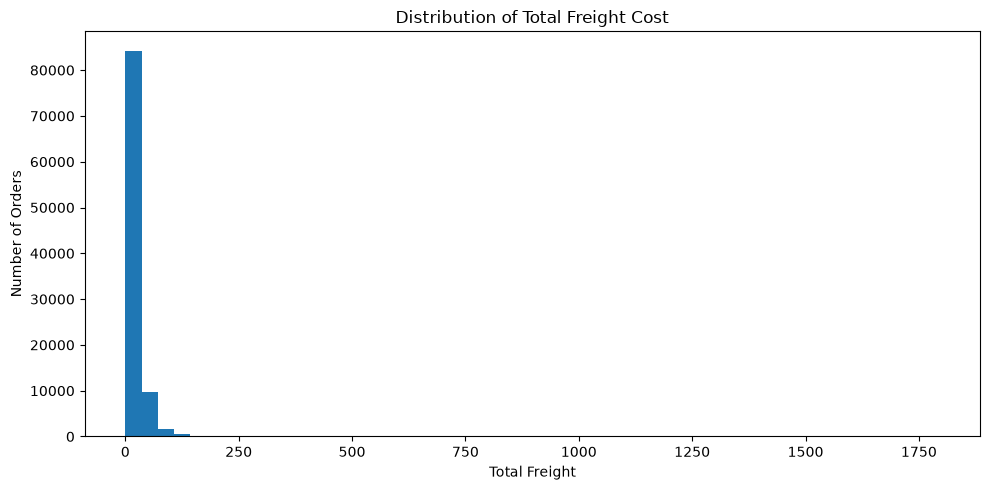

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(delivery_data['total_freight'], bins=50)

plt.title('Distribution of Total Freight Cost')
plt.xlabel('Total Freight')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

Graph interpretation
- Most orders ka freight cost lower range mein concentrated hai.
- Freight cost badhne ke saath orders ki frequency sharply decrease ho rahi hai.
- Right side mein long tail hai, jo kuch extremely high freight values indicate karta hai.
- Maximum freight ₹1,794.96 hai, jabki median sirf ₹17.17 tha.
Yani kuch extreme freight orders average aur standard deviation ko influence kar rahe hain.
Notebook finding
The total freight cost distribution is highly right-skewed. Most orders have freight costs concentrated in a relatively low range, while a small number of orders have exceptionally high freight costs, creating a long right tail. The mean freight cost (22.79) is higher than the median (17.17), indicating the influence of extreme values. These high freight values will be investigated further before deciding whether any treatment is required.

Next: item_count analysis
Ab hum item_count ka descriptive analysis karenge. Isse pata chalega orders mein kitne items typically hote hain aur numerical variation kaisa hai.

In [ ]:
delivery_data['item_count'].describe()

count    96470.000000
mean         1.142210
std          0.538824
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         21.000000
Name: item_count, dtype: float64

Next step: Order price vs delivery outcome
Simple statistics se distribution samajh aata hai, lekin prediction project mein humein ye bhi dekhna hai ki Late orders ki order value On-time orders se different hai ya nahi.

Pehle ek comparison plot banayenge:

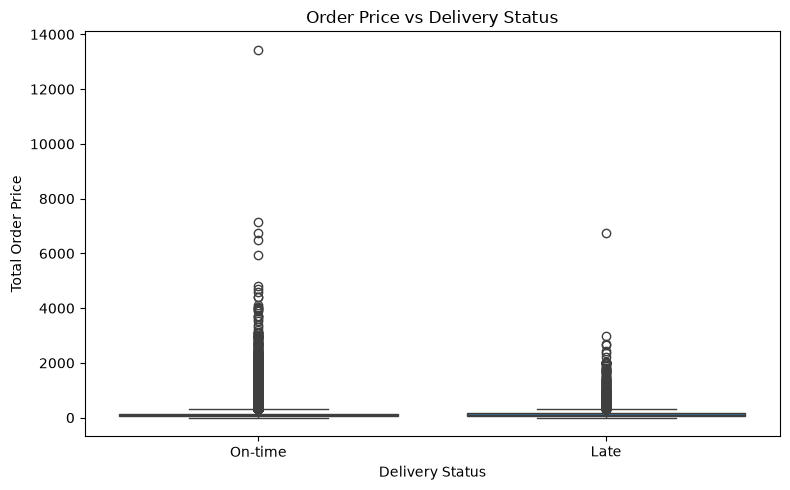

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=delivery_data,
    x='delivery_status',
    y='total_price'
)

plt.title('Order Price vs Delivery Status')
plt.xlabel('Delivery Status')
plt.ylabel('Total Order Price')

plt.tight_layout()
plt.show()

In [ ]:
delivery_data.groupby('delivery_status')['total_price'].agg(
    ['mean', 'median', 'std', 'min', 'max']
)

,mean,median,std,min,max
delivery_status,,,,,
Late,150.891390,90.05,229.634560,3.54,6729.0
On-time,136.033675,85.39,207.443114,0.85,13440.0


Graph ko dhyan se dekho — is plot mein ek important limitation hai: extreme high-price outliers ki wajah se boxes compressed ho gaye hain, isliye median aur middle 50% ka difference visually clear nahi dikh raha.
1. Kya observe ho raha hai?
- On-time aur Late dono groups mein high-price outliers hain.
- On-time orders mein extreme maximum value Late orders se bhi higher hai.
- Dono groups ki main distributions kaafi compressed aur overlapping dikh rahi hain.
- Sirf is graph ko dekhkar ye conclude nahi kar sakte ki high-price orders zyada late hote hain.
Yani abhi total_price aur delivery status ke beech strong visual separation nahi dikh rahi, but exact relationship quantify karna zaroori hai.
2. Boxplot ko readable banate hain
High-value outliers ki wajah se boxplot compressed hai. log scale use karenge taaki lower price range ka distribution clearly dikhe.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

orders = pd.read_csv('../data/raw/olist_orders_dataset.csv')
order_items = pd.read_csv('../data/raw/olist_order_items_dataset.csv')
customers = pd.read_csv('../data/raw/olist_customers_dataset.csv')
sellers = pd.read_csv('../data/raw/olist_sellers_dataset.csv')

In [18]:
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

In [19]:
delivered_orders = orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_customer_date'].notna()) &
    (orders['order_estimated_delivery_date'].notna())
].copy()

delivered_orders.shape

(96470, 8)

In [21]:
delivered_orders['delivery_delay_days'] = (
    delivered_orders['order_delivered_customer_date'] -
    delivered_orders['order_estimated_delivery_date']
).dt.days

delivered_orders['delivery_status'] = np.where(
    delivered_orders['delivery_delay_days'] > 0,
    'Late',
    'On-time'
)

delivered_orders['actual_delivery_days'] = (
    delivered_orders['order_delivered_customer_date'] -
    delivered_orders['order_purchase_timestamp']
).dt.total_seconds() / (24 * 60 * 60)

delivered_orders['estimated_delivery_days'] = (
    delivered_orders['order_estimated_delivery_date'] -
    delivered_orders['order_purchase_timestamp']
).dt.total_seconds() / (24 * 60 * 60)

In [22]:
order_features = order_items.groupby('order_id').agg(
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    item_count=('order_item_id', 'count')
).reset_index()

In [23]:
order_features.head()

,order_id,total_price,total_freight,item_count
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,1
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,1
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,1
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,1


In [24]:
delivery_data = delivered_orders.merge(
    order_features,
    on='order_id',
    how='left'
)

In [25]:
delivery_data.shape

(96470, 15)

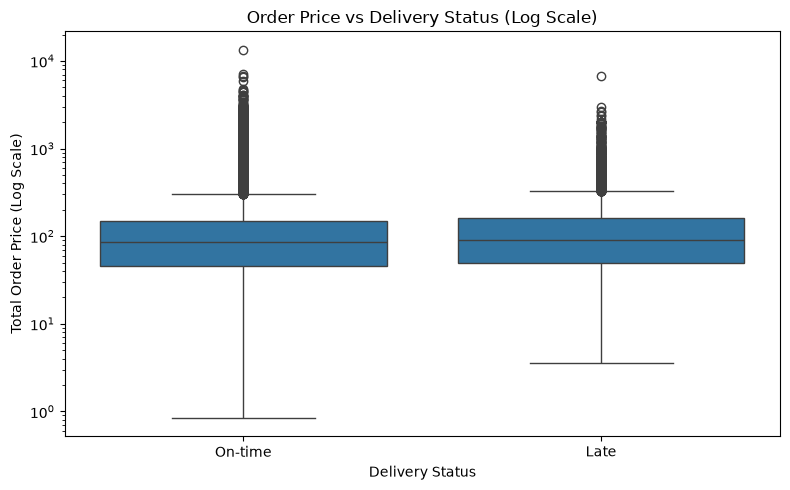

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=delivery_data,
    x='delivery_status',
    y='total_price'
)

plt.yscale('log')

plt.title('Order Price vs Delivery Status (Log Scale)')
plt.xlabel('Delivery Status')
plt.ylabel('Total Order Price (Log Scale)')

plt.tight_layout()
plt.show()

In [27]:
delivery_data.groupby('delivery_status')['total_price'].agg(
    ['mean', 'median', 'std', 'min', 'max']
)

,mean,median,std,min,max
delivery_status,,,,,
Late,150.891390,90.05,229.634560,3.54,6729.0
On-time,136.033675,85.39,207.443114,0.85,13440.0


Notebook finding
Ye Markdown cell notebook mein add kar sakti ho:
The comparison of order prices across delivery statuses shows that late orders have slightly higher mean and median prices than on-time orders. However, the difference between the two groups is relatively small, and their distributions overlap considerably. Both groups contain high-value outliers, with the maximum order value being higher among on-time orders. Therefore, order price alone does not appear to provide a strong visual distinction between late and on-time deliveries.

3. Next analysis — Freight cost vs delivery status
Ab total_freight ko Late aur On-time groups ke beech compare karenge. Freight cost logistics se directly related feature hai, so iska relationship investigate karna useful hai.

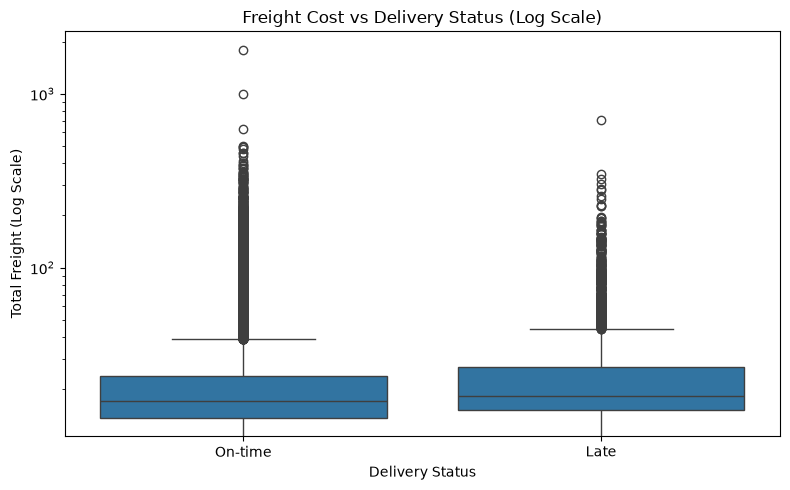

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=delivery_data,
    x='delivery_status',
    y='total_freight'
)

plt.yscale('log')

plt.title('Freight Cost vs Delivery Status (Log Scale)')
plt.xlabel('Delivery Status')
plt.ylabel('Total Freight (Log Scale)')

plt.tight_layout()
plt.show()

In [29]:
delivery_data.groupby('delivery_status')['total_freight'].agg(
    ['mean', 'median', 'std', 'min', 'max']
)

,mean,median,std,min,max
delivery_status,,,,,
Late,25.247596,18.23,23.715586,0.0,711.33
On-time,22.606944,17.06,21.383993,0.0,1794.96


1. Boxplot interpretation
- Median: Late orders ki median freight cost On-time orders se thodi higher dikh rahi hai.
- Spread (IQR): Late orders ka middle spread thoda wider hai, yani freight values mein variability slightly higher hai.
- Outliers: Dono groups mein high freight outliers hain. On-time group mein extreme freight values aur bhi high hain.
- Overlap: Dono distributions kaafi overlap karti hain, isliye freight cost alone se delivery status clearly distinguish nahi hota.
2. Numerical comparison se verify karte hain
Visual observation ko exact values se confirm karne ke liye ye cell run karo

Interpretation
- Mean: Late orders ka average freight cost 25.25 hai, jabki On-time orders ka 22.61 — approximately 2.64 higher.
- Median: Late orders mein median freight 18.23 vs On-time 17.06 — difference small hai.
- Standard deviation: Late group mein variation slightly higher hai.
- Maximum: On-time orders mein extreme freight cost (1,794.96) Late orders (711.33) se kaafi higher hai.
Mean aur median dono Late orders mein higher hain, lekin difference relatively small hai. Dono groups ka overlap kaafi hai.
2. Notebook finding
Ye Markdown cell add kar lo:
The comparison of freight costs across delivery statuses shows that late orders have slightly higher mean and median freight costs than on-time orders. However, the differences are relatively small, and both groups show substantial overlap in their distributions. Extremely high freight values are also present in on-time orders. Therefore, freight cost alone does not appear to clearly distinguish late deliveries from on-time deliveries.

3. Next feature: item_count vs delivery status
Ab dekhna hai ki orders mein items ki quantity aur late delivery ke beech relationship hai ya nahi.

Item count discrete feature hai (1, 2, 3, 4, ...), isliye boxplot ke bajay hum har item count ke liye late delivery percentage calculate karenge. Ye zyada meaningful hoga.

Next cell run karo:

In [30]:
item_delay_analysis = delivery_data.groupby('item_count').agg(
    total_orders=('order_id', 'count'),
    late_orders=('delivery_status', lambda x: (x == 'Late').sum())
)

item_delay_analysis['late_percentage'] = (
    item_delay_analysis['late_orders'] /
    item_delay_analysis['total_orders'] * 100
)

item_delay_analysis

,total_orders,late_orders,late_percentage
item_count,,,
1,86835,6024,6.937295
2,7392,397,5.370671
3,1306,64,4.900459
4,495,23,4.646465
5,193,9,4.663212
6,191,16,8.376963
7,22,0,0.000000
8,8,0,0.000000
9,3,0,0.000000


3. Visualization
Ab late percentage ko bar chart mein visualize karenge. Rare categories (7 se zyada items) ko abhi exclude karenge, taaki graph misleading na ho.

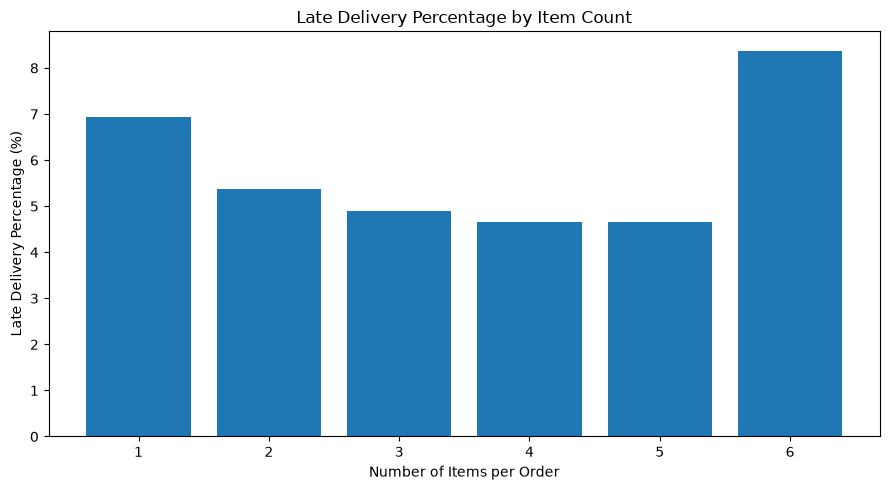

In [31]:
item_delay_plot = item_delay_analysis[
    item_delay_analysis['total_orders'] >= 100
]

plt.figure(figsize=(9, 5))

plt.bar(
    item_delay_plot.index,
    item_delay_plot['late_percentage']
)

plt.title('Late Delivery Percentage by Item Count')
plt.xlabel('Number of Items per Order')
plt.ylabel('Late Delivery Percentage (%)')
plt.xticks(item_delay_plot.index)

plt.tight_layout()
plt.show()

Step 1: is_late target column banao
Jupyter Notebook mein new cell mein ye code paste karke Shift + Enter karo:

In [32]:
delivery_data['is_late'] = (
    delivery_data['delivery_status'] == 'Late'
).astype(int)

Iska meaning:
- On-time → 0
- Late → 1
Ye binary target hai, jise hum future mein Machine Learning model ko predict karne ke liye use karenge.

Step 2 — Correlation matrix

In [33]:
correlation_features = [
    'estimated_delivery_days',
    'total_price',
    'total_freight',
    'item_count',
    'is_late'
]

correlation_data = delivery_data[correlation_features]

correlation_matrix = correlation_data.corr()

correlation_matrix

,estimated_delivery_days,total_price,total_freight,item_count,is_late
estimated_delivery_days,1.000000,0.076451,0.239725,0.016427,-0.033484
total_price,0.076451,1.000000,0.411178,0.153479,0.017859
total_freight,0.239725,0.411178,1.000000,0.439386,0.030777
item_count,0.016427,0.153479,0.439386,1.000000,-0.015251
is_late,-0.033484,0.017859,0.030777,-0.015251,1.000000


estimated_delivery_days → estimated delivery duration



total_price → order ki total price



total_freight → total shipping charges



item_count → order mein kitne items hain



is_late → target (0 = On-time, 1 = Late)

- Estimated delivery days (-0.033): Very weak negative relationship.
- Total price (+0.018): Almost no linear relationship.
- Total freight (+0.031): Very weak positive relationship.
- Item count (-0.015): Almost no linear relationship.
Overall, in features ka target ke saath individual linear correlation bahut low hai. Lekin iska matlab ye nahi ki ye features prediction mein useless hain. Machine Learning models nonlinear relationships aur multiple features ke combined patterns bhi capture kar sakte hain.

Dusra observation:
- total_price & total_freight = 0.41 → moderate positive correlation.
- total_freight & item_count = 0.44 → moderate positive correlation.
Ye reasonable hai, kyunki multiple items hone par freight cost badh sakti hai

Step 4 — Final heatmap

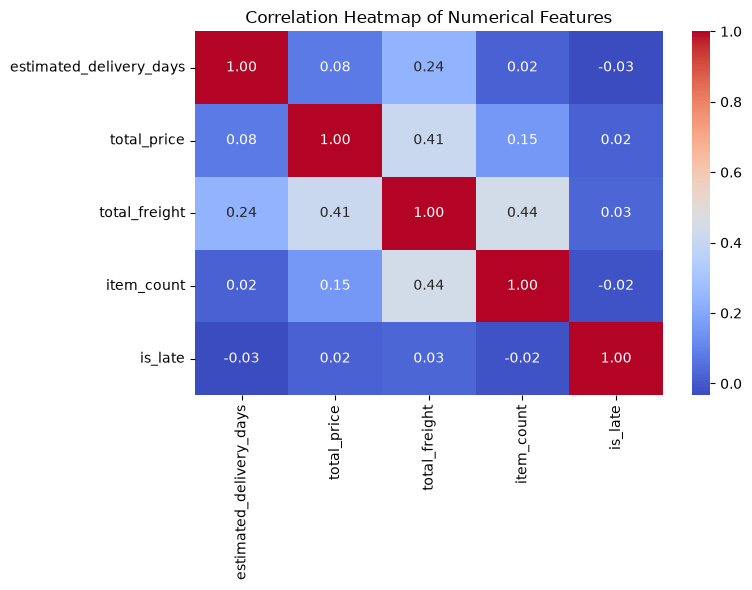

In [34]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

Final EDA conclusions
- Late deliveries: Approximately 6.77% orders late, while 93.23% were on time.
- Delivery delay: Most orders delivered before their estimated date, but late deliveries have a long positive tail.
- Customer location: Late delivery percentage varies considerably by customer state.
- Seller location: Seller states also show differences in late delivery rates; some states have higher late percentages.
- Order price: Late orders had slightly higher prices, but the distributions overlapped substantially.
- Freight: Late orders had slightly higher freight costs, but the difference was small.
- Item count: Most orders contain one item. Item count alone did not show a clear relationship with late deliveries.
- Correlation: All numerical features showed very weak linear correlations with the target.

Step 1 — Features (X) aur Target (y) separate karna
Model ko input features denge aur usse predict karna hoga ki order late hoga ya nahi.

In [35]:
X = delivery_data[
    [
        'estimated_delivery_days',
        'total_price',
        'total_freight',
        'item_count'
    ]
]

y = delivery_data['is_late']

Samjho:
- X → model ko di jane wali input information (features).
- y → actual answer jo model ko predict karna hai (0 = On-time, 1 = Late).
Humne abhi sirf basic numerical features liye hain. Baad mein location aur date-related features add karke model improve kar sakte hain.

Step 2 — Data ko training aur testing mein divide karna
Model ko data ke ek portion se sikhayenge aur baaki unseen data par test karenge, taaki pata chale model actually kitni achhi prediction karta hai.

In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

test_size=0.2 → 20% data testing ke liye, 80% training ke liye.



random_state=42 → har baar same split milega, reproducibility ke liye.



stratify=y → Late aur On-time ka proportion training aur testing dono mein approximately same rahega.

Split verify karna

In [37]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Late percentage in train:", y_train.mean() * 100)
print("Late percentage in test:", y_test.mean() * 100)

X_train: (77176, 4)
X_test: (19294, 4)
Late percentage in train: 6.7728309318959266
Late percentage in test: 6.774126671504095


Step 3 — First ML model: Logistic Regression
Ab hum apna first classification model train karenge.

Logistic Regression ek classification algorithm hai jo predict karega:
- 0 → On-time
- 1 → Late
Pehle features scale karna zaroori hai kyunki total_price, total_freight, estimated_delivery_days aur item_count ki ranges alag hain.

In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

StandardScaler() → features ko standard scale par convert karta hai.



fit_transform(X_train) → training data se scaling parameters learn karta hai aur scale bhi karta hai.



transform(X_test) → wahi training parameters test data par apply karta hai.

In [39]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

- LogisticRegression() → classification model initialize kar rahe hain.
- random_state=42 → reproducible behavior ke liye.
- model.fit(X_train_scaled, y_train) → model training; ye features aur labels ke patterns learn karega.
Training ke baad model learned patterns use karke unseen orders ke late hone ki prediction kar sakega.

In [40]:
y_pred = model.predict(X_test_scaled)

Step 5 — Model evaluation
Ab check karenge ki model ne kitni predictions sahi ki aur Late orders ko kitna identify kiya.

In [41]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      1.00      0.96     17987
           1       0.00      0.00      0.00      1307

    accuracy                           0.93     19294
   macro avg       0.47      0.50      0.48     19294
weighted avg       0.87      0.93      0.90     19294



Ye result bahut important hai — aur honestly, tumhara first model ek useful problem expose kar raha hai. Model 93% accuracy dikha raha hai, lekin Late orders ke liye ek bhi order identify nahi kar paya.
1. Result ko samjho
Metric	On-time (0)	Late (1)
Precision	0.93	0.00
Recall	1.00	0.00
F1-score	0.96	0.00
Support	17,987	1,307

- On-time recall = 1.00: Model ne almost/all On-time orders identify kar liye.
- Late recall = 0.00: Actual 1,307 Late orders mein se model ne ek bhi identify nahi kiya.
- Late precision = 0.00: Late prediction hi nahi ki, isliye precision zero hai.
- Accuracy = 93%: Ye misleading hai, kyunki dataset mein 93% orders pehle se On-time hain.
Agar model har order ko On-time bol de, to bhi lagbhag 93% accuracy mil jayegi. Lekin hamara project ka objective late deliveries predict karna hai, isliye ye model abhi useful nahi hai.
2. Aisa kyu hua?
Hamare dataset mein:
- On-time = 93.23%
- Late = 6.77%
Logistic Regression ka default prediction threshold 0.5 hai. Model currently Late hone ki probability ko 0.5 se upar nahi le ja pa raha, isliye saare orders ko class 0 predict kar raha hai.

Is problem ko Class Imbalance kehte hain.
3. Ab verify karte hain

In [42]:
print("Actual class distribution:")
print(y_test.value_counts())

print("\nPredicted class distribution:")
print(pd.Series(y_pred).value_counts())

Actual class distribution:
is_late
0    17987
1     1307
Name: count, dtype: int64

Predicted class distribution:
0    19289
1        5
Name: count, dtype: int64


Model ne sirf 5 orders ko Late predict kiya, jabki actually 1,307 orders Late the.

Isliye default Logistic Regression threshold 0.5 hamare imbalanced dataset ke liye effective nahi raha.
2. Ab kya karenge?
Hum Logistic Regression ka second model train karenge, lekin is baar:

class_weight='balanced'

Ye parameter minority class (Late) ko zyada importance deta hai, taaki model Late orders ko ignore na kare.
Step 6 — Balanced Logistic Regression
Ye cell run karo:

In [43]:
model_balanced = LogisticRegression(
    class_weight='balanced',
    random_state=42
)

model_balanced.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the follo

Step 7 — Predictions

In [44]:
y_pred_balanced = model_balanced.predict(X_test_scaled)

In [45]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_balanced))

              precision    recall  f1-score   support

           0       0.94      0.59      0.72     17987
           1       0.08      0.53      0.15      1307

    accuracy                           0.58     19294
   macro avg       0.51      0.56      0.43     19294
weighted avg       0.89      0.58      0.68     19294



Ab dekho, Balanced Logistic Regression ne exactly wahi change kiya jo hum chahte the — Late orders detect karna start kiya. Lekin ab false alarms kaafi badh gaye hain.
1. Dono models ka comparison
Metric (Late class)	First Model	Balanced Model
Precision	0.00	0.08
Recall	0.00	0.53
F1-score	0.00	0.15
Accuracy	0.93	0.58

2. Balanced model ne kya achieve kiya?
- Recall 53%: 1,307 actual late orders mein se approximately 693 detect kiye.
- Precision 8%: Model jin orders ko Late bol raha hai, unmein sirf 8% actually late hain.
- Accuracy 58%: Accuracy kaafi decrease hui, kyunki model ab zyada orders ko Late predict kar raha hai.
Matlab first model bahut conservative tha, jabki balanced model ab zyada aggressively Late orders identify kar raha hai.

3. Confusion Matrix — next step
Ab hum exact dekhna chahte hain ki kitne orders correctly aur incorrectly predict hue.

Run this cell:

In [46]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_balanced)

cm

array([[10534,  7453],
       [  620,   687]])

1. Confusion Matrix interpretation
Prediction result	Count	Meaning
True Negative (TN)	10,534	On-time correctly predicted
False Positive (FP)	7,453	On-time orders ko galti se Late bola
False Negative (FN)	620	Late orders miss ho gaye
True Positive (TP)	687	Late orders correctly detect kiye

- Model ne 687 late orders detect kiye.
- 620 late orders miss hue.
- Lekin 7,453 false alarms bhi diye.
Yahi Balanced Logistic Regression ka trade-off hai: Late deliveries pakadne mein improvement, lekin false positives bahut zyada.
2. Ab threshold tuning karenge
Balanced model default threshold 0.5 use kar raha hai. Hum probability ko manually adjust karke dekh sakte hain ki false alarms kam hote hain ya nahi, while retaining acceptable recall.

Pehle probabilities nikalte hain:

In [47]:
y_prob = model_balanced.predict_proba(X_test_scaled)[:, 1]

predict_proba() har order ke Late hone ki probability deta hai. [:, 1] ka matlab sirf Late class (1) ki probability lena.

Abhi sirf ye cell run karo. Next step mein different thresholds test karke compare karenge—jaise 0.5, 0.6, 0.7—taaki Late detection aur false alarms ke beech better balance find kar sakein.

Step 8 — Threshold comparison
Ye cell run karo:

In [48]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:
    y_threshold_pred = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, y_threshold_pred)
    recall = recall_score(y_test, y_threshold_pred)
    f1 = f1_score(y_test, y_threshold_pred)

    print(f"Threshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1 Score: {f1:.3f}")
    print("-" * 30)

Threshold: 0.3
Precision: 0.068
Recall: 0.998
F1 Score: 0.127
------------------------------
Threshold: 0.4
Precision: 0.070
Recall: 0.982
F1 Score: 0.131
------------------------------
Threshold: 0.5
Precision: 0.084
Recall: 0.526
F1 Score: 0.145
------------------------------
Threshold: 0.6
Precision: 0.099
Recall: 0.056
F1 Score: 0.071
------------------------------
Threshold: 0.7
Precision: 0.105
Recall: 0.017
F1 Score: 0.029
------------------------------


1. Threshold comparison
Threshold	Precision	Recall	F1
0.3	6.8%	99.8%	0.127
0.4	7.0%	98.2%	0.131
0.5	8.4%	52.6%	0.145
0.6	9.9%	5.6%	0.071
0.7	10.5%	1.7%	0.029

Is behavior ko samjho
- Threshold kam karne par model zyada orders ko Late classify karta hai → recall badhta hai, false alarms bhi badhte hain.
- Threshold badhane par model conservative hota hai → predictions kam karta hai, recall sharply decrease ho sakta hai.
- Threshold 0.5 par is table mein F1 best hai, lekin precision abhi bhi low hai.
2. Abhi ka best Logistic Regression result
Late class ke liye currently threshold 0.5 ka F1-score best (0.145) hai. Lekin operationally, agar goal maximum late orders catch karna ho, threshold 0.4 bhi consider kar sakte hain—98.2% recall ke saath, though false alarms bahut high hain.

3. Logistic Regression baseline complete
Humne 3 experiments kiye:
1. Default Logistic Regression — baseline; Late recall 0%.
2. Balanced Logistic Regression — Late recall 53%.
3. Threshold tuning — recall aur precision ke trade-off ko explore kiya.
Ab Logistic Regression experiments complete. Threshold abhi final lock nahi karenge.
Next: Random Forest
Next model Random Forest Classifier try karenge. Ye multiple decision trees use karta hai aur nonlinear relationships aur feature interactions learn kar sakta hai.

Tree-based models ko scaling ki zarurat nahi hoti, isliye Random Forest ke liye hum original X_train aur X_test use karenge.

Ready ho to next cell se Random Forest training start karte hain.

Chalo 💪 ab Random Forest Classifier start karte hain. Logistic Regression ke baad ye hamara second ML algorithm hoga.
Step 1 — Random Forest model train karna
Random Forest multiple decision trees banata hai aur unke predictions combine karke final prediction deta hai. Ye nonlinear patterns bhi learn kar sakta hai.

Is baar scaled data ki jagah original X_train aur X_test use karenge, kyunki Random Forest ko feature scaling ki zarurat nahi hoti.

Ye cell run karo:

In [49]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

Parameters ka meaning:
- n_estimators=100 → 100 decision trees banenge.
- random_state=42 → results reproducible rakhne ke liye.
- class_weight='balanced' → minority class Late ko extra importance.
- n_jobs=-1 → available CPU cores use karna.

Step 2 — Random Forest predictions

In [50]:
rf_pred = rf_model.predict(X_test)

In [51]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.93      0.96      0.95     17987
           1       0.13      0.07      0.09      1307

    accuracy                           0.90     19294
   macro avg       0.53      0.52      0.52     19294
weighted avg       0.88      0.90      0.89     19294



Random Forest ka result aa gaya. Aur interesting baat ye hai ki Random Forest ne balanced Logistic Regression se better accuracy di, lekin Late deliveries identify karne mein abhi bhi weak hai.
1. Random Forest result
Metric	On-time (0)	Late (1)
Precision	0.93	0.13
Recall	0.96	0.07
F1-score	0.95	0.09

- Accuracy = 90%
- Late recall = 7%
- Late precision = 13%
Matlab model sirf 7% actual late deliveries catch kar raha hai. Accuracy achhi dikh rahi hai, lekin hamare main objective ke hisaab se performance weak hai.
2. Logistic Regression vs Random Forest
Model	Late Precision	Late Recall	Late F1	Accuracy
Logistic Regression (default)	0.00	0.00	0.00	93%
Logistic Regression (balanced)	0.08	0.53	0.15	58%
Random Forest (balanced)	0.13	0.07	0.09	90%

Balanced Logistic Regression currently has the highest Late recall and F1. Random Forest has higher accuracy but catches very few late orders at its default threshold.
3. Next experiment — Random Forest threshold tuning
Random Forest ke probabilities check karenge. Default threshold 0.5 ki jagah lower threshold par iska performance improve ho sakta hai.

Run this cell:

In [52]:
rf_prob = rf_model.predict_proba(X_test)[:, 1]

Step — Random Forest threshold tuning

In [53]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:
    rf_threshold_pred = (rf_prob >= threshold).astype(int)

    precision = precision_score(y_test, rf_threshold_pred, zero_division=0)
    recall = recall_score(y_test, rf_threshold_pred, zero_division=0)
    f1 = f1_score(y_test, rf_threshold_pred, zero_division=0)

    print(f"Threshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1 Score: {f1:.3f}")
    print("-" * 30)

Threshold: 0.3
Precision: 0.113
Recall: 0.235
F1 Score: 0.153
------------------------------
Threshold: 0.4
Precision: 0.123
Recall: 0.138
F1 Score: 0.130
------------------------------
Threshold: 0.5
Precision: 0.132
Recall: 0.081
F1 Score: 0.101
------------------------------
Threshold: 0.6
Precision: 0.129
Recall: 0.044
F1 Score: 0.065
------------------------------
Threshold: 0.7
Precision: 0.105
Recall: 0.019
F1 Score: 0.032
------------------------------


Step 1 — Model comparison table

In [54]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Logistic Regression (Balanced)',
        'Random Forest (0.5)',
        'Random Forest (0.3 Threshold)'
    ],
    'Late Precision': [0.00, 0.08, 0.132, 0.113],
    'Late Recall': [0.00, 0.53, 0.081, 0.235],
    'Late F1 Score': [0.00, 0.15, 0.101, 0.153],
    'Accuracy': [0.93, 0.58, 0.90, np.nan]
})

model_comparison

,Model,Late Precision,Late Recall,Late F1 Score,Accuracy
0,Logistic Regression,0.000,0.000,0.000,0.93
1,Logistic Regression (Balanced),0.080,0.530,0.150,0.58
2,Random Forest (0.5),0.132,0.081,0.101,0.90
3,Random Forest (0.3 Threshold),0.113,0.235,0.153,NaN


Result interpretation
- Logistic Regression (default): 93% accuracy, lekin Late recall 0% — late orders identify nahi karta.
- Logistic Regression (balanced): Late recall 53% — sabse zyada late orders identify kiye, lekin false alarms bahut zyada.
- Random Forest (0.5): Precision sabse achha (13.2%) hai, tested models mein default threshold par, lekin recall sirf 8.1%.
- Random Forest (0.3): F1 = 0.153, hamare tested experiments mein highest F1 (balanced Logistic Regression ke 0.15 se slightly higher).
Isliye koi ek model har metric mein best nahi hai. Model selection business requirement par depend karega—maximum Late detection chahiye ya false alarms kam rakhne hain.

Step 2 — Project conclusion

## Model Evaluation & Conclusion

Multiple classification experiments were performed to predict late deliveries using the Olist ecommerce dataset.

The initial Logistic Regression model achieved approximately 93% accuracy but failed to identify late deliveries due to class imbalance. After applying class balancing, the recall for late deliveries improved to 53%, although precision remained low, indicating a high number of false-positive predictions.

A Balanced Random Forest model was also trained. Different prediction thresholds were evaluated to improve late-delivery detection. The Random Forest model with a threshold of 0.3 achieved an F1-score of 0.153 and recall of 23.5%.

### Key Findings
- The dataset is highly imbalanced, with late deliveries representing approximately 6.77% of orders.
- Accuracy alone is not a reliable evaluation metric for this problem.
- Class balancing improved the model's ability to detect late deliveries.
- Threshold adjustment significantly influenced precision and recall.
- The evaluated features showed weak individual linear correlations with late-delivery outcomes.

### Conclusion
The experiments demonstrate that predicting late deliveries is challenging using the selected features. Balanced Logistic Regression achieved the highest recall among the tested models, while Random Forest with a lower threshold achieved a slightly higher F1-score. Further improvements may be possible through additional features such as customer and seller locations, order purchase dates, product characteristics, and richer logistics information.

This project highlights the importance of evaluating classification models using precision, recall, and F1-score rather than accuracy alone when dealing with imbalanced datasets.

Step 1 — Create Train, Validation & Test sets
Ab hum data ko 3 parts mein divide karenge:
- Train (60%) → model ko train karna
- Validation (20%) → threshold/model selection karna
- Test (20%) → final evaluation, only once

In [55]:
from sklearn.model_selection import train_test_split

# First separate 20% final test data
X_temp, X_test_final, y_temp, y_test_final = train_test_split(
    X, y,
    test_size=0.20,
    random_state=2026,
    stratify=y
)

# Split remaining 80% into training and validation
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,
    random_state=2026,
    stratify=y_temp
)

print("Training set:", X_train_final.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test_final.shape)

print("\nLate percentage:")
print("Train:", y_train_final.mean() * 100)
print("Validation:", y_val.mean() * 100)
print("Test:", y_test_final.mean() * 100)

Training set: (57882, 4)
Validation set: (19294, 4)
Test set: (19294, 4)

Late percentage:
Train: 6.7723990186932035
Validation: 6.774126671504095
Test: 6.774126671504095


Step 2 — Train Balanced Logistic Regression
Pehle Logistic Regression ko train karenge. Scaling sirf training data par fit hogi; validation data par wahi scaler apply hoga.

In [56]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Feature scaling
scaler_final = StandardScaler()

X_train_final_scaled = scaler_final.fit_transform(X_train_final)
X_val_scaled = scaler_final.transform(X_val)

# Train balanced Logistic Regression
lr_final = LogisticRegression(
    class_weight='balanced',
    random_state=42
)

lr_final.fit(X_train_final_scaled, y_train_final)

# Validation probabilities
lr_val_prob = lr_final.predict_proba(X_val_scaled)[:, 1]

print("Model training completed.")
print("Validation probabilities generated:", len(lr_val_prob))

Model training completed.
Validation probabilities generated: 19294


Is step mein kya ho raha hai?
- fit_transform() — training data se scaling parameters learn karta hai.
- transform() — validation ko training ke learned parameters se scale karta hai.
- class_weight='balanced' — minority class (late orders) ko zyada weight deta hai.
- predict_proba() — late delivery hone ki probability deta hai, jisse hum threshold select kar sakenge.

Step 3 — Validation threshold comparison

In [57]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

threshold_results = []

for threshold in thresholds:
    y_val_pred = (lr_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, y_val_pred, zero_division=0)
    recall = recall_score(y_val, y_val_pred, zero_division=0)
    f1 = f1_score(y_val, y_val_pred, zero_division=0)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df

,Threshold,Precision,Recall,F1 Score
0,0.1,0.067741,1.000000,0.126887
1,0.2,0.067787,1.000000,0.126967
2,0.3,0.067975,0.999235,0.127290
3,0.4,0.070104,0.989288,0.130930
4,0.5,0.084876,0.522571,0.146034
5,0.6,0.127527,0.062739,0.084103
6,0.7,0.111111,0.014537,0.025710


Probability threshold decide karta hai ki model kisi order ko Late (1) predict kare ya On-time (0).
- 0.5 → probability 50% ya usse zyada hone par Late
- 0.3 → probability 30% ya usse zyada hone par Late
- Threshold kam karne par generally Recall badhta hai, lekin false positives bhi badh sakte hain.

Results ka interpretation
Threshold	Precision	Recall	F1	Meaning
0.1	0.068	1.000	0.127	Almost saare late orders detect, lekin bahut false alarms
0.2	0.068	1.000	0.127	Same behaviour
0.3	0.068	0.999	0.127	Almost every late order detected
0.4	0.070	0.989	0.131	High recall, low precision
0.5	0.085	0.523	0.146	Best F1 among tested thresholds
0.6	0.128	0.063	0.084	Most late orders missed
0.7	0.111	0.015	0.026	Very few late orders detected

Hum 0.5 select karenge, kyunki tested thresholds mein iska F1 score highest 0.146 hai. Validation data par threshold 0.5 hi best balance de raha hai, though precision is still low.
- Threshold 0.4 → Recall 98.9%, par false positives bahut high.
- Threshold 0.5 → Recall 52.3%, F1 0.146, tested thresholds mein best F1.
- Threshold 0.6 → Precision improve hoti hai, lekin late deliveries detect karna bahut kam ho jata hai.
Important: 0.5 ko hum validation set ke basis par select kar rahe hain. Ab test set par threshold tuning nahi karenge.
Next step
Ab selected model ko final test data par evaluate karenge, aur final precision, recall, F1, confusion matrix aur accuracy report karenge. Ye hi hamara final unbiased evaluation hoga.

Step 4 — Final evaluation on test data

In [58]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Scale final test data using the training-fitted scaler
X_test_final_scaled = scaler_final.transform(X_test_final)

# Predict probabilities
test_prob = lr_final.predict_proba(X_test_final_scaled)[:, 1]

# Apply selected threshold
selected_threshold = 0.5
y_test_final_pred = (test_prob >= selected_threshold).astype(int)

# Final metrics
print("Selected Threshold:", selected_threshold)
print("Accuracy:", accuracy_score(y_test_final, y_test_final_pred))
print("Late Precision:", precision_score(y_test_final, y_test_final_pred))
print("Late Recall:", recall_score(y_test_final, y_test_final_pred))
print("Late F1 Score:", f1_score(y_test_final, y_test_final_pred))

print("\nClassification Report:\n")
print(classification_report(
    y_test_final,
    y_test_final_pred,
    target_names=["On-time", "Late"]
))

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test_final, y_test_final_pred))

Selected Threshold: 0.5
Accuracy: 0.5889913962890018
Late Precision: 0.08361624544197158
Late Recall: 0.5087987758224942
Late F1 Score: 0.14362850971922247

Classification Report:

              precision    recall  f1-score   support

     On-time       0.94      0.59      0.73     17987
        Late       0.08      0.51      0.14      1307

    accuracy                           0.59     19294
   macro avg       0.51      0.55      0.44     19294
weighted avg       0.89      0.59      0.69     19294


Confusion Matrix:

[[10699  7288]
 [  642   665]]


Outcome	Count	Meaning
TN	10,699	On-time orders correctly predicted
FP	7,288	On-time orders flagged as late
FN	642	Late orders missed
TP	665	Late orders correctly detected

Business interpretation: Model 1,307 actual late orders mein se 665 detect kar pa raha hai—lagbhag half. Lekin 7,288 on-time orders ko bhi late flag kar raha hai, isliye unnecessary alerts bahut zyada hain.
3. Final model conclusion
Balanced Logistic Regression ne 50.88% recall achieve kiya, yani actual late deliveries mein se roughly half detect hui. However, 8.36% precision ka matlab hai ki late predict kiye gaye orders mein bahut kam actually late the.

Is model ko abhi operational deployment ke liye reliable nahi keh sakte, but as a baseline ML project it demonstrates class imbalance handling, threshold selection, and evaluation methodology.

# Train, Validation & Test Split

The dataset was divided into training, validation, and test sets to support model training, threshold selection, and final evaluation.

### Dataset Split
- **Training Set (60%)** — Used to train the machine learning models.
- **Validation Set (20%)** — Used to compare prediction thresholds and select the appropriate decision threshold.
- **Test Set (20%)** — Reserved for final model evaluation on unseen data.

Stratified splitting was used to preserve the proportion of late and on-time orders across all three datasets.

A fixed random state was used to ensure reproducibility.

### Why Three Sets?

The validation set helps make model selection decisions without using the final test set. The test set is kept separate until the final evaluation to provide a more reliable estimate of model performance.

4. Notebook mein final conclusion

# Model Building

Multiple classification models were trained to evaluate their ability to identify late deliveries.

### Models Evaluated

**1. Logistic Regression (Baseline)**

A standard Logistic Regression model was trained as a baseline to understand the initial classification performance without class balancing.

**2. Balanced Logistic Regression**

Class weights were adjusted using `class_weight='balanced'` to address the imbalance between late and on-time orders. This approach assigns greater importance to the minority class during training.

**3. Random Forest Classifier**

A Random Forest classifier was used to capture potential nonlinear relationships and feature interactions that Logistic Regression may not capture effectively.

### Feature Scaling

StandardScaler was applied to the features used by Logistic Regression. The scaler was fitted on training data only and then applied to the validation/test data to prevent data leakage.

Random Forest was trained without feature scaling because tree-based models do not require standardized numerical features.

# Threshold Tuning

The classification threshold determines how the model's predicted probability is converted into a binary class prediction.

By default, a threshold of 0.5 is used. However, for an imbalanced dataset, adjusting the threshold can help improve the detection of the minority class.

Different thresholds were evaluated using the validation dataset.

### Evaluation Metrics
- **Precision:** Proportion of predicted late orders that were actually late.
- **Recall:** Proportion of actual late orders correctly identified by the model.
- **F1-score:** Harmonic mean of precision and recall.

A lower threshold generally increases late-delivery recall but may also increase false-positive predictions.

The threshold was selected based on validation F1-score, and the final test dataset was not used for threshold selection.

# Final Model Evaluation

The selected model and decision threshold were evaluated on the held-out test dataset.

The test dataset was not used during model training or threshold selection. It was reserved for final performance assessment.

### Final Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

Special attention was given to the `Late` class because late deliveries represent the minority class and are the primary business concern.

The confusion matrix was used to examine correctly identified late deliveries, missed late deliveries, and false-positive alerts.

## Final Model Evaluation

A balanced Logistic Regression model was trained to predict late deliveries 
using a train-validation-test approach.

The prediction threshold was selected using the validation dataset, 
and the final model was evaluated on an unseen test dataset.

### Final Test Results
- Accuracy: 58.90%
- Late Precision: 8.36%
- Late Recall: 50.88%
- Late F1-score: 14.36%
- Selected Threshold: 0.50

The model identified 665 late deliveries out of 1,307 actual late deliveries,
while missing 642 late orders. However, it generated a large number of 
false-positive predictions (7,288), indicating low precision.

### Key Learnings
- Accuracy is misleading when the target class is imbalanced.
- Class weighting improves minority-class detection.
- Threshold selection impacts the precision-recall trade-off.
- Validation data should be used for model selection and threshold tuning.
- The final test set should remain untouched until final evaluation.

### Conclusion
The model achieved approximately 51% recall for late deliveries but 
showed poor precision. The selected numerical features alone were not 
sufficient to reliably distinguish late and on-time deliveries.

Further improvement may require richer features, such as seller and customer 
locations, order purchase time, product categories, and historical seller 
delivery performance.

# Feature Engineering

Feature engineering was performed to transform the raw e-commerce data into an order-level dataset suitable for machine learning.

Order item data was aggregated at the order level to create additional numerical features.

### Features Created

- **Estimated Delivery Days:** Expected delivery duration calculated from the order purchase date and estimated delivery date.
- **Total Price:** Sum of product prices for each order.
- **Total Freight:** Total freight charges associated with each order.
- **Item Count:** Number of items included in each order.

### Target Variable

The target variable `is_late` was created from the actual delivery date and estimated delivery date.

- `0` — On-time delivery
- `1` — Late delivery

Features representing actual delivery duration and delivery delay were excluded from model predictors to prevent target leakage.

The resulting dataset was used for classification model development.

## Model Performance Summary

| Metric | Final Result |
|---|---:|
| Selected Model | Balanced Logistic Regression |
| Decision Threshold | 0.50 |
| Accuracy | 58.90% |
| Late Precision | 8.36% |
| Late Recall | 50.88% |
| Late F1-score | 14.36% |
| True Positives (Late detected) | 665 |
| False Negatives (Late missed) | 642 |
| False Positives | 7,288 |
| True Negatives | 10,699 |

### Interpretation

The model detected approximately half of all late deliveries in the test set. However, precision was low, meaning that many orders predicted as late were actually on time.

The results highlight the challenge of predicting delivery delays with the currently selected features and demonstrate why precision, recall, and F1-score are important for imbalanced classification problems.

## Key Findings from EDA

- Approximately **6.77%** of orders were late, indicating a significant class imbalance.
- Most orders were delivered earlier than their estimated delivery dates.
- Delivery duration and delay distributions were right-skewed, with some extreme delivery cases.
- Several extreme delivery records showed unusual date patterns and were flagged for investigation rather than automatically removed.
- Late-delivery rates varied considerably across customer states.
- Most orders contained a single item.
- Order price and freight values were right-skewed, with a few high-value outliers.
- Numerical features showed weak individual linear correlations with the late-delivery target.
- Late and on-time orders had overlapping distributions for price and freight, suggesting these features alone were not sufficient to clearly distinguish late deliveries.

### EDA Conclusion

The exploratory analysis revealed an imbalanced target variable, geographical variation in delivery delays, and several data anomalies. The selected numerical features showed limited individual linear relationships with late-delivery outcomes, highlighting the difficulty of predicting delivery delays using these features alone.

# Final Conclusion

This project explored the prediction of late deliveries using the Olist Brazilian E-Commerce dataset.

The analysis revealed that late deliveries represent a minority of orders, making the problem challenging due to class imbalance. Multiple classification approaches were evaluated, including Logistic Regression, Balanced Logistic Regression, and Random Forest.

Balanced Logistic Regression improved late-delivery detection compared with the baseline model. Validation-based threshold evaluation was performed, and the selected model was evaluated on a separate test dataset.

The final model achieved a late-delivery recall of approximately 50.88%, but its precision remained low at 8.36%, indicating a high number of false-positive predictions.

### Limitations
- Limited predictive power of the selected numerical features.
- High class imbalance.
- Weak individual correlations between selected features and the target.
- Large number of false-positive predictions.

### Future Improvements
- Include customer and seller geographical information.
- Incorporate product categories and order characteristics.
- Explore historical seller delivery performance.
- Experiment with more informative logistics-related features.
- Explore advanced classification and feature engineering approaches.

Overall, this project demonstrates an end-to-end machine learning workflow, including data preprocessing, exploratory analysis, feature engineering, model training, class imbalance handling, threshold selection, and final evaluation.